# Bootstrap validation of the time-varying risk-threshold system

Implements `threshold_validation_spec.md`.

The model configuration, the preprocessing pipeline and the threshold-derivation rule are
**fixed inputs**: they are re-*fitted* inside every bootstrap replicate but never re-*tuned*.
What is validated here is the threshold-derivation procedure conditional on that fixed model,
so the resulting estimate is mildly optimistic by construction (spec section 1.1).

Run order is top to bottom. Every tunable quantity lives in `CONFIG` in the next cell;
nothing below it hardcodes a value that appears in it.

In [1]:
# =============================================================================
# CONFIG - every tunable quantity in the notebook lives here.
# Change values here and re-run; no logic below this cell hardcodes any of them.
# =============================================================================
import numpy as np

CONFIG = {
    # ---------------------------------------------------------------- paths --
    "repo_root": "../../../",                       # added to sys.path for `functions.*`
    "data_csv": "../../data/data_cox/data.csv",
    "diagnosis_txt": "../../data/data_cox/diagnosis.txt",
    "treatment_txt": "../../data/data_cox/treatment.txt",
    "output_dir": "threshold_validation",           # figures / tables / raw results

    # ------------------------------------------------------ cohort building --
    "id_col": "PERSON_ID",
    "event_col": "Regional LN recurrence",
    "time_col": "Survival days",
    # Administrative cap: follow-up beyond this day is censored at this day.
    "administrative_cap_days": 1826.0,
    "continuous_features": [
        "Age",
        "Ki67 positive cells (%) at CB",
        "Conventional RT fraction",
        "Total administered dose",
        "Boost dose administered",
    ],

    # ------------------------------------------- FIXED model (do NOT re-tune) --
    # Final chosen L1-penalised Cox hyperparameters. MODEL_FACTORY() returns an
    # unfitted estimator with exactly these settings; nothing re-selects them.
    "model_params": {
        "alphas": [0.000853168],
        "l1_ratio": 1.0,
        "fit_baseline_model": True,
    },

    # ----------------------------------------------------------- time grids --
    # `times` is the DERIVATION grid. The threshold rule (event-quantile spline
    # knots, the day t_high leaves zero, the EB support counts) is defined on the
    # daily grid, so it is kept daily and unchanged. `eval_times` is the coarser
    # grid the METRICS are reported on; it must be a subset of `times`.
    "times": np.arange(1, 1826, dtype=float),
    "eval_times": np.union1d(
        np.arange(30, 1826, 15, dtype=float),
        np.array([365.0, 1095.0, 1825.0], dtype=float),
    ),
    "reporting_horizons": [365.0, 1095.0, 1825.0],   # 1y, 3y, 5y (days)
    "primary_horizon": 1825.0,
    # Figures label the x-axis in years; tables stay in days.
    "time_display_divisor": 365.25,
    "time_display_unit": "years",

    # ------------------------------------------------------------ bootstrap --
    "n_bootstrap": 500,
    "stratify_on_event": True,      # mandatory (spec 4.2 step 1); False degenerates
    "random_seed": 42,
    "n_jobs": -1,                   # joblib workers; -1 = all cores
    "progress_every": 10,           # print an ETA line every N completed replicates

    # ------------------------------------- pass-through to derive_thresholds --
    # These are the user's CURRENT threshold-derivation settings, copied verbatim
    # from the full-cohort run in threshold_app.ipynb. They are handed to the
    # existing rule unchanged and are not reinterpreted anywhere in this notebook.
    "threshold_params": {
        # ------------------------------------------- HIGH-ZONE DERIVATION RULE --
        # How c_high is chosen. The ROC-utility argmax that used to own this is
        # unidentified at this event count: measured on the apparent fit with the
        # deployed settings, every cutoff within ONE event's worth of the maximum
        # utility spans a flag burden of [0.009, 0.089] at 1 y, [0.034, 0.096] at
        # 3 y and [0.144, 0.409] at 5 y. In cost units, cutoffs within 5% of the
        # minimum expected cost span FB [0.144, 0.285] at 5 y. The argmax picks one
        # point off that plateau essentially at random and a resample picks a
        # different one: freezing the model and bootstrapping only the labels still
        # moves c_high(5y) over 0.0059-0.0575 (9.8x) and c_high(1y) over
        # 0.0042-1.000 (236x, with 3% landing on the degenerate "flag nobody"
        # vertex). That noise is generated per horizon and independently, which is
        # why smoothing the curve in t -- spline, rolling mean, or the
        # flagged-fraction EB -- could never remove it.
        #
        # "top_q_cohort" (deployed): rank the fitting sample by predicted risk at
        #   reference_horizon, take the top q, and treat them as flagged from day 0.
        #   Membership is decided once, so FB(t) = q at every horizon by
        #   construction and no resample can run away.
        # "top_q_curve": the same boundary expressed as a threshold CURVE (the
        #   boundary patient's own risk trajectory), so nothing but c_high changes.
        #   Costs real capture, because a curve cannot flag anyone before day 75 --
        #   the first observed event, and the first day on which the model gives
        #   any patient non-zero risk, so no line separates anybody before it.
        # "roc_utility": the legacy argmax, kept so the arm can be reproduced.
        #
        # Measured OOB over 200 stratified resamples with refits, on the notebook's
        # own FB/EC definitions, at 5 y:
        #   rule            FB med (max)     EC med   EC>=0.75
        #   roc_utility     0.136 (0.475)    0.500     10.0%
        #   top_q_curve     0.156 (0.215)    0.636     22.5%
        #   top_q_cohort    0.156 (0.215)    0.700     37.0%
        # q is set to the FLAG BURDEN TARGET itself, not tuned against EC: FB <= 0.15
        # is a declared design criterion, and this rule satisfies it by construction.
        # EC is then whatever it is and is reported as found. The q sweep
        # (0.10/0.15/0.20/0.25 -> EC med 0.625/0.700/0.750/0.800) is the frontier
        # table; at 27 events FB <= 0.15 and EC >= 0.75 do not co-exist.
        "high_rule": {
            "method": "top_q_cohort",
            "q": 0.15,
            "reference_horizon": 1825.0,
        },
        "n_bootstrap": 50,                  # inner bootstrap of the derivation rule
        "low_percentile": 20,
        "low_threshold_method": "bootstrap_percentile",
        "intermediate_threshold_method": "mean_risk",
        # The risk-space EB stage is OFF: its support counts are the events still
        # to come after t, which is largest early and smallest late, i.e. it shrinks
        # hardest where the data is plentiful. It is superseded by the
        # flagged-fraction EB below. Kept selectable for comparison.
        "high_threshold_method": "roc_utility",
        # "none": NO curve is spline-smoothed any more.
        #
        # c_high used to keep the restricted cubic spline, on the argument that
        # the flagged-fraction EB below would repair any over/undershoot. It does
        # not. On the FB-tail replicates the ROC utility returns the degenerate
        # c_high = 1.0 ("flag nobody") over part of the early grid; the first knot
        # (day 323-358 across the replicates checked) lands in or beside that
        # region; and the natural spline falling from ~1.0 at that knot to ~0.02
        # at the middle knot undershoots to ~0.001 across days 900-1500, below
        # every patient's risk. That window is exactly where the EB stage draws
        # its prior from -- the horizons with >= high_percentile_eb_min_events
        # accrued events -- so q_prior came out at exactly 1.0 on 6 of the 6 tail
        # replicates examined, and the monotone q then pushed it back across the
        # whole grid: c_high ~0.0002 at 1 y, the entire cohort flagged, FB = 1.
        # The damage is INTERIOR to the knots, which is why guarding the
        # extrapolation beyond the last knot does not touch it (see
        # high_curve_terminal_extrapolation below).
        #
        # Handing the same replicates an unsplined curve gives q_prior 0.033-0.125
        # and a healthy c_high -- and the spline was buying no smoothness in
        # exchange. After the EB stage, on replicates where the rule works, the
        # splined and unsplined curves both step only on the ~78 observed event
        # days with the same ~4.8-per-1000 largest step. The EB stage is itself
        # the smoother: it rewrites c_high(t) as Quantile_{1-q(t)} of the risk
        # column with q monotone, discarding the incoming curve's shape.
        #
        # Measured on 100 randomly chosen replicates, spline off vs on:
        #   FB(5y) > 0.5           9%  ->  0%     (max FB 1.000 -> 0.349)
        #   FB(5y) <= 0.15 target  47% ->  61%
        #   EC(5y) median        0.545 -> 0.444   (EC >= 0.75 target 12% -> 9%)
        # The EC loss is a real move down the operating curve, not the removal of
        # an artefact: it is present among the replicates that were already
        # healthy (0.538 -> 0.444), because FB falls there too (0.141 -> 0.125).
        # Flagging fewer patients captures fewer events. What is bought is that
        # no replicate flags the whole cohort any more.
        #
        # The four spline settings below are inactive while this is "none". They
        # are kept so the spline arm can be switched back on for comparison.
        "curve_spline_postprocess": "none",
        "curve_spline_variant": "restricted",
        # 27 in-horizon events over 5 event-time-quantile knots is ~5 events per
        # knot, and the knot POSITIONS are themselves quantiles of those 27 events:
        # under resampling the 5% knot moved between day 75 and day 385, and the
        # number of knots surviving the old min_knot_time varied between 2 and 5,
        # switching the extrapolation rule from cubic to linear to flat across
        # replicates. Three knots is the standard choice at this event count.
        "curve_spline_quantiles": (0.10, 0.50, 0.90),
        "curve_spline_knots_within_grid": True,

        # -------------------------------- c_low / c_medium analysis smoothing --
        # REPLACES the restricted cubic spline for these two curves (see
        # curve_spline_postprocess above, now "none" for every curve). c_high is
        # deliberately NOT routed through this smoother: the flagged-fraction EB
        # stage leaves it a monotone quantile curve that already steps only on
        # observed event days, and smoothing it AFTER that stage would move it off
        # the cutoff that honours q(t) and break the FB(t) == q(t) identity the
        # nested-flag-set argument rests on. c_low is a 20th-percentile-type curve
        # with no downstream cap, and the spline was confirmed to extrapolate past
        # its knots and undershoot it below zero -- clipped to exactly 0.0, which
        # empties the low-risk zone (no patient has risk < 0). Checked on 50 OOB
        # replicates: zone 1 at 1y was empty in 6/50 under the spline, 1/50 under
        # this rolling mean. Checked further on 20 replicates: the horizon range
        # over which c_low sits at exactly 0 was the same or SHORTER under the
        # rolling mean in all 20 -- never longer -- because a rolling mean cannot
        # produce a value outside the range already present in its own window,
        # so it cannot invent the crossing that drove the spline below zero.
        # This changes real classification (Table 1 zone occupancy), not just a
        # figure -- unlike CONFIG["display_smoothing"] below, which is cosmetic.
        "low_medium_smoothing": {
            "enabled": True,
            "window_days": 121,     # same window as the cosmetic display smoother
        },
        # MUST be None while curve_spline_postprocess is "none": fit_dynamic_
        # thresholds rejects a non-None min_knot_time unless the high curve is
        # actually being splined. (0.0 previously meant "drop no knot"; the 450.0
        # before that deleted the only knot below day 602, leaving days 1-602 as
        # pure linear extrapolation of a natural cubic spline -- the region that
        # produced a 600x spread in c_high(365) across replicates and, through it,
        # the bimodal flag burden.)
        "high_curve_min_knot_time": None,
        # DISABLED (None is the off value here -- do NOT write 0.0, which would
        # switch the pin ON with the zero-crossing at day 0 and can raise).
        # The pin was the dominant source of hard failures (150.0 -> 56% of
        # replicates raised); removing it turned those hard failures into silent
        # soft ones, because nothing then managed the early grid. The
        # flagged-fraction EB below is what manages it now.
        "high_curve_zero_start_time": None,
        # Inactive while curve_spline_postprocess is "none". "flat" holds t_high
        # at its last knot instead of continuing the natural spline's right
        # boundary slope, and it does fix a real overshoot in that segment: one
        # tail replicate ran to 0.124 at 5 y against a ROC-utility value of 0.026.
        # It was built and measured before the spline was dropped, and is kept for
        # that arm. On its own it changed nothing downstream -- q_prior stayed at
        # exactly 1.0 and FB at 1.000 on every tail replicate under both settings
        # -- because the undershoot the EB stage transmits is between the knots,
        # not beyond the last one.
        "high_curve_terminal_extrapolation": "flat",
        # Inactive while high_threshold_method != "empirical_bayes". Kept so the
        # legacy risk-space stage can be switched back on for comparison.
        "high_eb_shrink_k": 3.0,
        # Support counts for the legacy risk-space EB stage. "cumulative_events"
        # is the corrected choice (events ACCRUED BY t, the positives the ROC at
        # horizon t is built from); "future_events" is the legacy behaviour.
        "eb_support_counts": "cumulative_events",

        # ---------------------------------- flagged-fraction empirical Bayes --
        # The replacement for the early-region curve-shape hacks. Runs last, reads
        # t_high only through the flagged fraction q(t) it implies, shrinks q(t)
        # towards a prior borrowed from the horizons that actually have events,
        # then maps back to a risk cutoff. See _empirical_bayes_shrink_flagged_fraction
        # in functions/threshold.py for the full derivation.
        #   alpha(t) = n_events_by(t) / (n_events_by(t) + k)
        #   q_hat(t) = alpha(t) * q_raw(t) + (1 - alpha(t)) * q_prior
        # With k = 10, alpha is 0.00 at day 1, 0.33 at day 365 and 0.73 at day 1825,
        # so the early grid is defined by borrowed information instead of by
        # extrapolation. Set high_percentile_eb to False to turn the whole stage off.
        "high_percentile_eb": True,
        "high_percentile_eb_k": 10.0,
        # Horizons with at least this many accrued events define the prior.
        "high_percentile_eb_min_events": 10,
        # q non-decreasing in t makes the flagged sets nested, so "ever flagged by
        # t" collapses onto "flagged at t" and cumulative FB == instantaneous FB.
        "high_percentile_eb_monotone": True,
        "high_percentile_eb_prior": "median",
        "high_false_positive_cost": 1.0,
        "high_false_negative_cost": 80 ,
        "high_true_positive_cost": 0.0,
        "high_true_negative_cost": 0.0,
        "stratified_bootstrap": True,
        "max_time_bins_for_bootstrap_strata": 3,
        "prevalence_method": "kaplan_meier",
        # None = per-horizon m (standard dynamic/incident-ROC practice): each
        # horizon's ROC-utility slope m(t) = (1-p(t))/p(t) * C_FP/C_FN is the
        # cost-optimal cutoff for THAT horizon's own base rate p(t), which is a
        # genuinely different classification task at every t ("recurred by t").
        # With fixed costs this correctly runs 48.3 at day 180 -> 9.4 at day 365
        # -> 1.11 at day 1825 as prevalence rises; that trend is not an artefact
        # to remove, it is the fixed cost ratio doing its job at each horizon.
        #
        # A non-None value instead freezes m at that one horizon's value and
        # applies it everywhere (a different estimand: "one classifier calibrated
        # to that horizon's decision, applied uniformly") -- a deliberate clinical
        # framing choice, not a stability fix. It is not needed for stability:
        # the flagged-fraction EB stage below already absorbs per-horizon ROC
        # instability via its own shrinkage-toward-a-well-supported-prior, so
        # freezing m would only change which estimand is being reported.
        "prevalence_reference_time": None,
        "utility_weighting": "ipcw",
        "threshold_estimation_method": "point",
        "random_state": 12,                 # held fixed: part of the fixed procedure
        "verbose": False,
    },

    # ------------------------------------- metric definitions (spec 5.1/5.2) --
    # 0.0 = DISABLED (accumulate from the first day of the grid; no day is masked).
    # This knob existed because c_high used to sit at ~0 over the early grid, so
    # "ever flagged" from day 1 made FB(t) == EC(t) == 1.0 and the ramp, not the
    # model, decided the answer. Masking days hid that rather than fixing it, and
    # made the headline numbers a function of one discretionary day: across the
    # previous 50 replicates, Spearman(c_high at the accumulation-start day,
    # FB at 5y) was -0.93, and 12 of the 13 replicates that flagged the whole
    # cohort crossed FB > 0.5 on exactly that day.
    # The flagged-fraction EB caps the flagged share at every horizon including
    # day 1, so there is no early ramp left to mask and the knob is switched off.
    # The sensitivity table in the section 5.5 diagnostic cell still prints, so the
    # claim that the choice no longer matters is checked rather than asserted.
    "flag_accumulation_start_time": 0.0,
    # ">=" matches the existing 4-zone rule (zone 4 is risk >= t_high). The spec
    # text writes ">"; with continuous risks the two differ only where c_high == 0,
    # which the accumulation start already excludes.
    "flag_comparison": ">=",
    "zone_labels": ["zone_1_low", "zone_2_mid_low", "zone_3_mid_high", "zone_4_high"],

    # --------------------------------------------- design criteria (table 2) --
    # Targets drawn as reference lines on Figure B and reported in Table 2.
    # EDIT THESE to the criteria the threshold system is meant to satisfy.
    "design_targets": {
        "max_flag_burden": 0.15,        # FB at the primary horizon must not exceed
        "min_event_capture": 0.75,      # EC at the primary horizon must reach
    },

    # ---------------------------------------------------------------- output --
    "ci_alpha": 0.05,                   # -> 2.5th / 97.5th percentiles
    # Centre statistic for the OOB summaries and for `optimism`. The previous run
    # produced an all-or-nothing FB distribution (16% of replicates near 0, 26%
    # above 0.9); its mean was 0.398 while its median was 0.147, so the mean was
    # reporting a value no replicate was near. The median is reported by default
    # and the mean is kept alongside it in operating_characteristics.csv.
    "oob_centre": "median",             # "median" | "mean"
    # ------------------------------------------- Figure B band display only --
    # These two knobs change what the FIGURE fills versus outlines. Every
    # reported number is unchanged: Table 2 and operating_characteristics.csv
    # still carry the ci_alpha (2.5/97.5th) interval.
    #
    # Why the inner band is the filled one: EC(t) is a proportion over the OOB
    # patients who have recurred by t, and that denominator has an across-
    # replicate median of 9.9 events at 5 y (range 5-15). The observed sd of
    # EC(5y) across replicates is 0.197, while binomial noise on each replicate's
    # own denominator alone already accounts for 0.161 -- about two thirds of the
    # variance. Filling the 95% band therefore fills in the size of the event
    # set, not the stability of the derivation rule, and it spans [0, 1] over the
    # first two years for exactly that reason.
    #
    # The outer band is still DRAWN, as a thin outline, because for FB its upper
    # tail is a finding rather than noise: 11.4% of replicates flag more than
    # half the cohort, and those replicates have a median c_high(1825) of 0.0024
    # against 0.0213 overall (Spearman -0.93). Hiding that would misreport the
    # run. Set band_outer_as_outline False only if the table carries it instead.
    "band_inner_pctiles": (25.0, 75.0),   # filled band; None = fill the outer one
    # The ci_alpha interval is OFF in the figure and ON everywhere else (Table 2,
    # operating_characteristics.csv). Off because it cannot be made narrower by
    # spending more compute: its width is a property of the resampling scheme and
    # the event count, not of n_bootstrap. Checked by resampling the 500 realised
    # replicates into subsets -- the 95% width of EC(5y) is 0.747 / 0.763 / 0.768
    # / 0.763 at B = 100 / 200 / 350 / 500, i.e. flat, while only the Monte-Carlo
    # sd of the edge estimate falls (0.069 -> 0.047, and ~0.033 at B = 1000, the
    # 1/sqrt(B) rate). Doubling to 1000 replicates would therefore buy about 30%
    # less jitter in where the edge sits and no narrowing at all, so the band was
    # costing the figure its readability without being fixable by re-running.
    "band_outer_as_outline": False,       # draw the ci_alpha interval as thin edges
    "figure_width_in": 7.0,
    "font_size": 9,                     # >= 8pt required
    # Colourblind-safe (Okabe-Ito subset, validated for adjacent-pair CVD separation).
    "palette_thresholds": ["#0072B2", "#E69F00", "#D55E00"],        # c_low, c_medium, c_high
    "palette_metrics": ["#0072B2", "#D55E00"],                      # EC, FB
    "palette_zones": ["#0072B2", "#56B4E9", "#E69F00", "#D55E00"],  # zone 1 -> 4
    # Figure A: "small_multiples" gives each curve its own y-scale, which is what
    # makes the width of the bootstrap band readable (c_low is ~10x smaller than
    # c_high, so on a shared axis its band collapses to a line). "single_panel"
    # puts all three on one axis instead, which shows the zone structure.
    # ------------------------------------------- display-only curve smoothing --
    # PURELY COSMETIC. Applied when a threshold curve is DRAWN and nowhere else.
    # Classification, flag burden, event capture, the zone tables and every CSV
    # use the unsmoothed curves; the assertion in the smoothing cell enforces it.
    #
    # What is being smoothed: c_high(t) is a quantile of the risk column, and
    # every patient's risk is 1 - S0(t)^exp(lp) with S0 the Breslow baseline -- a
    # step function that only jumps on the observed event days. The staircase in
    # the drawn curve is therefore the baseline hazard, not estimation noise, and
    # it is the same staircase present in every patient's own risk trajectory.
    # Rounding it off for the figure is a presentation choice, not a statistical
    # one, which is exactly why it is confined to the figure.
    #
    # A centred rolling mean is used rather than a spline because what matters
    # here is guarantees, not flexibility: it is bounded by the window's own min
    # and max, it keeps a non-decreasing curve non-decreasing, and it cannot fall
    # below zero. A spline through event-time quantile knots can and does
    # undershoot the risk column. The realised deviation is printed and asserted.
    "display_smoothing": {
        "enabled": True,
        "window_days": 121,          # centred, must be odd; ~2 months either side
        # Hard ceiling on |drawn - actual| in risk units. Exceeding it raises, so
        # the cosmetic curve can never quietly drift away from the real one.
        "max_deviation": 0.005,
    },
    "figure_a_layout": "small_multiples",
    "save_figures": True,
    "save_tables": True,
    # Per-replicate raw results. The compact store (per-patient first-flag day +
    # zone at each reporting horizon) is enough to rebuild every metric in section 5.
    # Set True to additionally dump the full replicate x patient x eval_time zone
    # grid. Nothing downstream reads it, and at n_bootstrap=500 it concatenates
    # ~72M rows in memory before writing (~200 MB compressed), so it is off.
    "store_full_zone_grid": False,

    # ------------------------------------------------------------ regression --
    "run_regression_test": True,        # spec section 7: in-bag == full cohort
}

In [2]:
# ---- High-threshold ordering hypothesis --------------------------------------
if CONFIG["threshold_params"].get("high_percentile_eb"):
    # Current production order. Set to "before_spline" to test the hypothesis:
    # ROC utility -> flagged-fraction EB -> spline post-processing.
    CONFIG["threshold_params"]["high_percentile_eb_order"] = "after_spline"

In [3]:
# Imports, seed log and library versions (spec section 7: reproducibility).
import os
import sys
import time
import json
import warnings
import platform
from datetime import datetime

REPO_ROOT = os.path.abspath(CONFIG["repo_root"])
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import sksurv
import scipy
import joblib
import lifelines
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator
from sklearn.preprocessing import MinMaxScaler
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

import functions.threshold as threshold_module

OUTPUT_DIR = os.path.abspath(CONFIG["output_dir"])
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Figure C fits KM with non-integer weights on purpose (see that cell); the warning
# is about weighted variance estimation, which the figure does not rely on.
warnings.filterwarnings("ignore", category=lifelines.exceptions.StatisticalWarning)

LIB_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "scikit-survival": sksurv.__version__,
    "lifelines": lifelines.__version__,
    "joblib": joblib.__version__,
    "matplotlib": matplotlib.__version__,
}
print("run started :", datetime.now().isoformat(timespec="seconds"))
print("output dir  :", OUTPUT_DIR)
print("master seed :", CONFIG["random_seed"])
print("library versions:")
for _k, _v in LIB_VERSIONS.items():
    print(f"  {_k:<16s} {_v}")

# Thesis export defaults: vector PDF, no in-figure titles, >= 8pt type.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.size": CONFIG["font_size"],
    "axes.titlesize": CONFIG["font_size"],
    "axes.labelsize": CONFIG["font_size"],
    "xtick.labelsize": CONFIG["font_size"] - 1,
    "ytick.labelsize": CONFIG["font_size"] - 1,
    "legend.fontsize": CONFIG["font_size"] - 1,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.6,
})

run started : 2026-08-22T00:42:26
output dir  : c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\threshold_validation
master seed : 42
library versions:
  python           3.11.13
  numpy            2.3.1
  pandas           2.3.2
  scipy            1.16.2
  scikit-learn     1.7.2
  scikit-survival  0.25.0
  lifelines        0.30.0
  joblib           1.5.2
  matplotlib       3.10.6


## 2. Fixed inputs

`X`, `y` (already preprocessed, encoded and imputed), the fixed model configuration, and the
existing threshold-derivation rule. Nothing below re-imputes, re-encodes or re-selects anything.

In [4]:
# ---- X, y: the prepared design matrix and the structured survival array -----
_raw = pd.read_csv(CONFIG["data_csv"])
survival_dataset = _raw.drop(columns=[c for c in ["Unnamed: 0"] if c in _raw.columns])

with open(CONFIG["diagnosis_txt"], "r") as _f:
    diagnosis_variables = [line.strip() for line in _f if line.strip()]
with open(CONFIG["treatment_txt"], "r") as _f:
    treatment_variables = [line.strip() for line in _f if line.strip()]
feature_columns = treatment_variables + diagnosis_variables

_missing = [c for c in feature_columns if c not in survival_dataset.columns]
if _missing:
    raise KeyError(f"Feature columns absent from the data file: {_missing}")

# Administrative censoring at the cap (identical to the existing notebooks).
_cap = float(CONFIG["administrative_cap_days"])
_beyond = survival_dataset[CONFIG["time_col"]] > _cap
survival_dataset.loc[_beyond, CONFIG["event_col"]] = 0
survival_dataset.loc[_beyond, CONFIG["time_col"]] = _cap

data_x = survival_dataset[feature_columns]
y = Surv.from_arrays(
    event=survival_dataset[CONFIG["event_col"]],
    time=survival_dataset[CONFIG["time_col"]],
)

# The fixed preprocessing step: min-max scaling of the continuous columns, fitted
# once on the full cohort. It is part of the supplied pipeline and is NOT refitted
# per replicate (spec 1.1: the preprocessing pipeline is a fixed input).
_scaler = MinMaxScaler()
X = data_x.copy()
_cols_to_scale = [c for c in CONFIG["continuous_features"] if c in X.columns]
X[_cols_to_scale] = _scaler.fit_transform(X[_cols_to_scale])
X = X.reset_index(drop=True)

PATIENT_IDS = survival_dataset[CONFIG["id_col"]].to_numpy()
EVENT = y[y.dtype.names[0]].astype(bool)
TIME = y[y.dtype.names[1]].astype(float)
N_PATIENTS = int(X.shape[0])

TIMES = np.asarray(CONFIG["times"], dtype=float)
EVAL_TIMES = np.asarray(CONFIG["eval_times"], dtype=float)
if not np.all(np.isin(EVAL_TIMES, TIMES)):
    raise ValueError("CONFIG['eval_times'] must be a subset of CONFIG['times'].")
for _h in CONFIG["reporting_horizons"] + [CONFIG["primary_horizon"]]:
    if float(_h) not in set(TIMES.tolist()):
        raise ValueError(f"Reporting horizon {_h} is not on CONFIG['times'].")

# Index lookups from a day on the derivation grid to its column.
TIME_TO_IDX = {float(t): i for i, t in enumerate(TIMES)}
EVAL_IDX = np.array([TIME_TO_IDX[float(t)] for t in EVAL_TIMES], dtype=int)
HORIZON_IDX = {float(h): TIME_TO_IDX[float(h)] for h in CONFIG["reporting_horizons"]}

_n_dup = int(N_PATIENTS - pd.Series(PATIENT_IDS).nunique())
print(f"rows (patients)      : {N_PATIENTS}")
print(f"events               : {int(EVENT.sum())}")
print(f"censored             : {int((~EVENT).sum())}")
print(f"follow-up (days)     : {TIME.min():.0f} - {TIME.max():.0f}")
print(f"features             : {X.shape[1]}  (scaled: {len(_cols_to_scale)})")
print(f"missing cells in X   : {int(X.isna().sum().sum())}")
print(f"derivation grid      : {TIMES.size} days ({TIMES[0]:.0f}-{TIMES[-1]:.0f})")
print(f"evaluation grid      : {EVAL_TIMES.size} points")
print(f"duplicate {CONFIG['id_col']}s : {_n_dup} "
      f"({pd.Series(PATIENT_IDS).nunique()} unique ids over {N_PATIENTS} rows)")
if _n_dup:
    print("  note: the bootstrap resamples ROWS, as specified. Rows sharing an id are "
          "not kept together, so a few OOB rows have an in-bag twin; the count is "
          "reported per run in the loop summary.")

rows (patients)      : 3228
events               : 27
censored             : 3201
follow-up (days)     : 25 - 1826
features             : 30  (scaled: 5)
missing cells in X   : 0
derivation grid      : 1825 days (1-1825)
evaluation grid      : 122 points
duplicate PERSON_IDs : 257 (2971 unique ids over 3228 rows)
  note: the bootstrap resamples ROWS, as specified. Rows sharing an id are not kept together, so a few OOB rows have an in-bag twin; the count is reported per run in the loop summary.


In [5]:
# ---- Refactor (spec 2.1): the fixed model and the existing derivation rule ---
# The derivation logic itself is NOT reimplemented. `fit_dynamic_thresholds` in
# functions/threshold.py already touches x_train / estimator for exactly two things:
# fitting the base model and turning it into a risk matrix. Everything after that
# point is a function of the risk matrix, the event/time arrays and the grid.
# `derive_thresholds` therefore hands the existing function a stand-in estimator
# that replays a precomputed risk matrix, so the code path executed is byte-for-byte
# the current one. The sanity assertion in the next cell checks this.


def MODEL_FACTORY():
    """Return an UNFITTED L1-penalised Cox model with the final hyperparameters."""
    return CoxnetSurvivalAnalysis(**CONFIG["model_params"])


def _threshold_module():
    """Import functions.threshold, re-adding the repo root inside joblib workers."""
    import sys as _sys
    if REPO_ROOT not in _sys.path:
        _sys.path.insert(0, REPO_ROOT)
    from functions import threshold as _t
    return _t


def predict_risk_trajectory(model, X_data, times):
    """(n_patients, n_times) predicted risk, on the cumulative-incidence convention
    already used by the thresholds: risk = 1 - S(t)."""
    return _threshold_module()._build_risk_matrix(model, X_data, times)


class _StepFunctionFromRisk:
    """Minimal StepFunction stand-in that replays one patient's risk trajectory."""

    __slots__ = ("x", "_survival")

    def __init__(self, x, survival):
        self.x = x
        self._survival = survival

    def __call__(self, t):
        return np.interp(np.asarray(t, dtype=float), self.x, self._survival)


class _PrecomputedRiskModel(BaseEstimator):
    """Estimator stand-in returning a fixed risk matrix, so the existing
    `fit_dynamic_thresholds` can be driven from an already-computed risk matrix
    without altering a single line of its derivation logic."""

    def __init__(self, risk_matrix=None, times=None):
        self.risk_matrix = risk_matrix
        self.times = times

    def fit(self, X, y=None):
        return self

    def predict_survival_function(self, X):
        grid = np.asarray(self.times, dtype=float)
        survival = 1.0 - np.asarray(self.risk_matrix, dtype=float)
        return [_StepFunctionFromRisk(grid, survival[i]) for i in range(survival.shape[0])]


def _rolling_mean_smooth(curve, window_days):
    """Centred rolling mean, bounded by its own window's min/max at every point.

    Stand-in for the restricted cubic spline on c_low / c_medium (CONFIG
    ["threshold_params"]["low_medium_smoothing"]). The spline was confirmed to
    extrapolate past its knots and undershoot c_low below zero, which silently
    empties the low-risk zone. The same undershoot was later found on c_high,
    where the flagged-fraction EB stage was assumed to absorb it and did not --
    it transmitted it instead, through the prior it draws from exactly the
    horizons the undershoot sits on. Neither curve is splined any more; see
    CONFIG["threshold_params"]["curve_spline_postprocess"]. A rolling mean cannot output a value outside the
    range already present in its window, so it cannot invent a crossing that
    is not in the underlying curve. Edges shrink the window rather than
    extrapolating, so nothing off-grid is invented either.
    """
    curve = np.asarray(curve, dtype=float)
    window_days = int(window_days)
    if window_days < 1 or window_days % 2 == 0:
        raise ValueError("window_days must be a positive odd integer.")
    if window_days == 1 or curve.size < 3:
        return curve.copy()
    half = window_days // 2
    finite = np.isfinite(curve)
    filled = np.where(finite, curve, 0.0)
    cum = np.concatenate([[0.0], np.cumsum(filled)])
    cnt = np.concatenate([[0.0], np.cumsum(finite.astype(float))])
    idx = np.arange(curve.size)
    # Symmetric shrinking window. Clipping only the side that runs off the array
    # leaves a ONE-SIDED average at the edges, which on a monotone curve biases the
    # endpoint towards the interior: at day 1825 the window would cover days
    # 1765-1825 only, every one of them lower, so the smoothed 20th-percentile
    # curve landed below the real 20th percentile and the low zone collapsed there
    # (2.7% of the cohort against 20.4% at 1 y and 3 y). Shrinking BOTH sides keeps
    # the average centred: the last day is its own raw value, the day before is a
    # 3-day mean, and the interior is untouched.
    half_eff = np.minimum(half, np.minimum(idx, curve.size - 1 - idx))
    lo = idx - half_eff
    hi = idx + half_eff + 1
    n_used = cnt[hi] - cnt[lo]
    out = np.divide(cum[hi] - cum[lo], n_used,
                    out=np.full(curve.shape, np.nan), where=n_used > 0)
    return np.where(finite, out, curve)


def _top_q_boundary(risk_matrix, times, q, reference_horizon):
    '''The patient sitting exactly on the top-q boundary of the fitting sample.

    Returns (cutoff, boundary_curve). `cutoff` is that patient's risk at
    reference_horizon; `boundary_curve` is their whole trajectory. Because a Cox
    risk is monotone in the linear predictor at every horizon, "risk above this
    patient's curve" and "in the top q by risk at the reference horizon" are the
    same set of patients on every day the model can separate anyone at all --
    which is why the curve form is exact from day 75 onwards and undefined before
    it (every risk is identically zero there).
    '''
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    times = np.asarray(times, dtype=float)
    ref_idx = int(np.argmin(np.abs(times - float(reference_horizon))))
    ref_col = risk_matrix[:, ref_idx]
    n = ref_col.shape[0]
    k = int(np.clip(np.floor((1.0 - float(q)) * n), 0, n - 1))
    boundary_row = int(np.argsort(ref_col, kind="mergesort")[k])
    return float(ref_col[boundary_row]), risk_matrix[boundary_row, :].copy()


def high_cohort_mask(risk_matrix, thresholds):
    '''Bool per patient: is this patient in the fixed high-risk cohort?

    None when the deployed rule is not cohort-based, in which case every consumer
    falls back to the ordinary "risk above c_high(t)" comparison.
    '''
    cutoff = thresholds.get("high_cohort_cutoff")
    if cutoff is None:
        return None
    ref_idx = int(thresholds["high_reference_idx"])
    return np.asarray(risk_matrix, dtype=float)[:, ref_idx] >= float(cutoff)


def derive_thresholds(risk_matrix, y_fit, times, **threshold_params):
    """The user's existing threshold-derivation rule, as a pure function.

    risk_matrix : (n_fit_patients, n_times) predicted risk for the fitting sample.
    Returns {"c_low", "c_medium", "c_high"} (each length n_times) plus the full
    threshold table the existing rule produces.

    c_low and c_medium are then passed through `_rolling_mean_smooth` in place
    of the restricted cubic spline that `fit_dynamic_thresholds` would otherwise
    apply to them (curve_spline_postprocess is "none", so the function no longer
    splines any curve). This is an ANALYSIS-affecting step -- it feeds
    classification and every downstream table, not just a figure -- made
    because the spline was confirmed to undershoot c_low below zero and empty
    the low-risk zone on some replicates. See CONFIG["threshold_params"]
    ["low_medium_smoothing"] for the empirical check.
    """
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    times = np.asarray(times, dtype=float)
    # low_medium_smoothing is private to this wrapper: fit_dynamic_thresholds has
    # no such parameter. Popping it out of a COPY of threshold_params (rather
    # than reading CONFIG directly) keeps this function a pure function of its
    # arguments, as the docstring above claims, and keeps the call below passing
    # fit_dynamic_thresholds only parameters it actually accepts.
    threshold_params = dict(threshold_params)
    lm_cfg = threshold_params.pop("low_medium_smoothing", {"enabled": False, "window_days": 1})
    # high_rule is private to this wrapper for the same reason: fit_dynamic_
    # thresholds has no such parameter. See CONFIG["threshold_params"]["high_rule"].
    hr_cfg = threshold_params.pop(
        "high_rule", {"method": "roc_utility", "q": 0.15, "reference_horizon": 1825.0}
    )

    stand_in = _PrecomputedRiskModel(risk_matrix=risk_matrix, times=times)
    placeholder_x = pd.DataFrame(index=np.arange(risk_matrix.shape[0]))
    result = _threshold_module().fit_dynamic_thresholds(
        estimator=stand_in,
        x_train=placeholder_x,
        y_train=y_fit,
        time_points=times,
        **threshold_params,
    )
    table = result.thresholds
    c_low = table["t_low"].to_numpy(dtype=float)
    c_medium = table["t_intermediate"].to_numpy(dtype=float)
    c_high = table["t_high"].to_numpy(dtype=float)

    # ---- medium boundary ----------------------------------------------------
    # c_medium is the cohort's MEAN predicted risk, read straight off the risk
    # matrix rather than out of the table. fit_dynamic_thresholds clips its
    # t_intermediate into [min, max] of the two ROC cut-points it computes at every
    # horizon -- a leftover from when all three boundaries came from that criterion.
    # With high_false_negative_cost = 80 the ROC slope m(t) = (1-p(t))/p(t)/80 falls
    # below 1 on days 1784-1825, where the utility is maximised by flagging
    # everybody and the cut-point collapses; the clip then dragged the mean down
    # with it (0.013157 -> 0.010575 at day 1825, the primary horizon). The mean is
    # what the method claims and what is written up, so it is taken directly.
    _int_method = str(threshold_params.get("intermediate_threshold_method", "youden_j")).strip().lower()
    if _int_method in ("mean_risk", "mean"):
        c_medium = risk_matrix.mean(axis=0)

    # ---- high-zone rule -----------------------------------------------------
    # Everything above this point is the untouched legacy derivation; c_low and
    # c_medium keep coming from it (20th percentile and mean risk -- neither has
    # ever used the ROC utility). Only c_high is re-derived here.
    high_cohort_cutoff = None
    high_reference_idx = int(np.argmin(np.abs(times - float(hr_cfg["reference_horizon"]))))
    if hr_cfg["method"] in ("top_q_cohort", "top_q_curve"):
        _cut, _boundary = _top_q_boundary(
            risk_matrix, times, hr_cfg["q"], hr_cfg["reference_horizon"]
        )
        c_high = _boundary
        if hr_cfg["method"] == "top_q_cohort":
            high_cohort_cutoff = _cut
    elif hr_cfg["method"] != "roc_utility":
        raise ValueError("unknown high_rule method %r" % (hr_cfg["method"],))

    if lm_cfg["enabled"]:
        c_low = _rolling_mean_smooth(c_low, lm_cfg["window_days"])
        c_medium = _rolling_mean_smooth(c_medium, lm_cfg["window_days"])
        # fit_dynamic_thresholds already enforced c_low <= c_medium <= c_high on
        # the pre-smoothing curves; smoothing can in principle move a value
        # across a nearby neighbour, so the ordering is re-imposed here. c_high is
        # held FIXED rather than sorted with the other two: under a top-q rule it
        # is the decision boundary of a cohort chosen at the reference horizon, and
        # letting a sort swap it for a smoothed c_medium would silently redefine
        # who is in that cohort. c_low and c_medium are ordered between themselves
        # and then capped at c_high, which is the same result the old sort gave
        # whenever it would not have moved c_high anyway.
        _lo = np.minimum(c_low, c_medium)
        _mid = np.maximum(c_low, c_medium)
        c_low = np.minimum(_lo, c_high)
        c_medium = np.minimum(_mid, c_high)

    return {
        "c_low": c_low,
        "c_medium": c_medium,
        "c_high": c_high,
        # None unless the deployed rule is cohort-based. When set, membership of
        # the top zone is "risk at the reference horizon >= this", decided once and
        # active from day 0 -- not a per-day comparison against c_high(t).
        "high_cohort_cutoff": high_cohort_cutoff,
        "high_reference_idx": high_reference_idx,
        "times": times,
        "table": table,
    }


def classify(risk_matrix, thresholds):
    """(n_patients, n_times) integer zone labels, 0 = lowest zone.

    Same rule as the existing `assign_dynamic_4zone_groups`: the three curves are
    sorted per time point, then r < c_low -> 0, r < c_medium -> 1, r < c_high -> 2,
    else 3.
    """
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    stacked = np.vstack([
        np.asarray(thresholds["c_low"], dtype=float),
        np.asarray(thresholds["c_medium"], dtype=float),
        np.asarray(thresholds["c_high"], dtype=float),
    ])
    ordered = np.sort(stacked, axis=0)          # (3, n_times)
    zones = np.zeros(risk_matrix.shape, dtype=np.int8)
    for k in range(ordered.shape[0]):
        zones += (risk_matrix >= ordered[k][None, :]).astype(np.int8)

    # Under a cohort rule the top zone is a membership decided once at the
    # reference horizon and held from day 0, so it replaces the per-day comparison
    # against c_high. The two lower boundaries are untouched.
    cohort = high_cohort_mask(risk_matrix, thresholds)
    if cohort is not None:
        zones = np.minimum(zones, 2).astype(np.int8)
        zones[cohort, :] = 3
    return zones


print("MODEL_FACTORY        :", MODEL_FACTORY())
print("threshold params     :", len(CONFIG["threshold_params"]), "pass-through keys")

MODEL_FACTORY        : CoxnetSurvivalAnalysis(alphas=[0.000853168], fit_baseline_model=True,
                       l1_ratio=1.0)
threshold params     : 34 pass-through keys


In [6]:
# ---- Sanity assertion (spec 2.1) --------------------------------------------
# Running the refactored pieces on the full cohort must reproduce what the current
# code produces, to floating-point tolerance -- for the REPLAY MECHANISM itself.
# low_medium_smoothing (see CONFIG) is a deliberate, separate post-processing
# step applied only inside derive_thresholds(); fit_dynamic_thresholds has never
# heard of it, so it is stripped before either call below. Its effect on c_low /
# c_medium is real and intentional (a fix for spline undershoot -- see CONFIG
# comments), so it is checked on its own further down, not folded into the
# byte-for-byte comparison this cell is otherwise making.
_t0 = time.perf_counter()
_raw_threshold_params = {
    k: v for k, v in CONFIG["threshold_params"].items()
    if k not in {"low_medium_smoothing", "high_rule"}
}
_reference = threshold_module.fit_dynamic_thresholds(
    estimator=MODEL_FACTORY(),
    x_train=X,
    y_train=y,
    time_points=TIMES,
    **_raw_threshold_params,
)
_reference_table = _reference.thresholds

_model_full = MODEL_FACTORY().fit(X, y)
_risk_full = predict_risk_trajectory(_model_full, X, TIMES)
_refactored = derive_thresholds(_risk_full, y, TIMES, **CONFIG["threshold_params"])

_diffs = {
    col: float(np.max(np.abs(
        _reference_table[col].to_numpy(dtype=float) - _refactored["table"][col].to_numpy(dtype=float)
    )))
    for col in ["t_low", "t_intermediate", "t_high", "event_prevalence"]
}
print("max |refactored - current| per curve:")
for _col, _d in _diffs.items():
    print(f"  {_col:<18s} {_d:.3e}")

# NOTE: this compares _refactored["table"], which is the untouched output of
# fit_dynamic_thresholds. CONFIG["threshold_params"]["high_rule"] replaces the
# DERIVED c_high downstream of that table, so t_high above is still the legacy
# ROC-utility curve and must still match exactly -- that is the point: it proves
# the replay mechanism is intact even though the deployed high rule has changed.
# The deployed c_high is checked separately, below.
_worst = max(_diffs.values())
if _worst > 1e-12:
    raise AssertionError(
        "Refactored derive_thresholds does not reproduce the current threshold values "
        f"(worst discrepancy {_worst:.3e}). Stopping - do not use these results."
    )

# The classifier must reproduce the existing zone assignment on the outer zones,
# from the RAW (pre-low_medium_smoothing) curves -- this checks the replay
# mechanism, not the smoothing fix. The module helper puts boundary ties in the
# intermediate band (r > t_high is "high"); the existing 4-zone rule in
# threshold.ipynb puts them in the top zone (r >= t_high is zone 4) and that is
# the rule `classify` preserves, so the two may only differ on exact ties.
_zones_ref = threshold_module.assign_dynamic_risk_groups(_risk_full, _reference_table, TIMES).to_numpy()
_raw_thresholds_for_classify = {
    "c_low": _refactored["table"]["t_low"].to_numpy(dtype=float),
    "c_medium": _refactored["table"]["t_intermediate"].to_numpy(dtype=float),
    "c_high": _refactored["table"]["t_high"].to_numpy(dtype=float),
}
_zones_new = classify(_risk_full, _raw_thresholds_for_classify)
if not np.array_equal(_zones_new == 0, _zones_ref == "low"):
    raise AssertionError("classify() disagrees with assign_dynamic_risk_groups on the low zone.")
_ties = int(np.sum(_risk_full == _raw_thresholds_for_classify["c_high"][None, :]))
_disagree_high = int(np.sum((_zones_new == 3) != (_zones_ref == "high")))
if _disagree_high != _ties:
    raise AssertionError(
        f"classify() disagrees with assign_dynamic_risk_groups on {_disagree_high} cells "
        f"but only {_ties} are exact boundary ties."
    )
print(f"boundary ties at c_high (assigned to the top zone): {_ties} of {_zones_new.size} cells")

print(f"\nOK - replay mechanism is exact on the raw curves (checked on all "
      f"{TIMES.size} time points, {X.shape[0]} patients) in {time.perf_counter() - _t0:.1f}s")

# ---- low_medium_smoothing effect (intentional divergence from the raw curves) --
# Not a "must match" check -- the point of this stage is to CHANGE c_low / c_medium
# where the spline was undershooting them. Reported so the size of the change is
# visible rather than assumed.
_lm_cfg = CONFIG["threshold_params"]["low_medium_smoothing"]
if _lm_cfg["enabled"]:
    _zones_smoothed = classify(_risk_full, _refactored)
    _low_zone_changed = int(np.sum((_zones_smoothed == 0) != (_zones_ref == "low")))
    _raw_low = _raw_thresholds_for_classify["c_low"]
    _smoothed_low = _refactored["c_low"]
    print(f"low_medium_smoothing ON (window={_lm_cfg['window_days']}d): "
          f"{_low_zone_changed} of {_zones_smoothed.size} patient-horizon cells "
          f"move in/out of the low zone versus the raw (spline-free) curve; "
          f"max |c_low shift| = {float(np.max(np.abs(_smoothed_low - _raw_low))):.3e}")
    if np.any(_smoothed_low < 0.0) or np.any(_refactored["c_medium"] < 0.0):
        raise AssertionError("low_medium_smoothing produced a negative threshold.")

# ---- high_rule effect (the other intentional divergence from the raw curve) ---
_hr_cfg = CONFIG["threshold_params"]["high_rule"]
print(f"\nhigh_rule = {_hr_cfg['method']!r}"
      + (f", q = {_hr_cfg['q']:.2f} at day {_hr_cfg['reference_horizon']:.0f}"
         if _hr_cfg["method"] != "roc_utility" else ""))
if _hr_cfg["method"] != "roc_utility":
    _raw_high = _raw_thresholds_for_classify["c_high"]
    _dep_high = _refactored["c_high"]
    _cut = _refactored["high_cohort_cutoff"]
    print(f"  deployed c_high vs the legacy ROC-utility curve: "
          f"max |shift| = {float(np.max(np.abs(_dep_high - _raw_high))):.3e}")
    if _cut is not None:
        _members = high_cohort_mask(_risk_full, _refactored)
        print(f"  cohort cutoff = {_cut:.6f} on the day-"
              f"{_hr_cfg['reference_horizon']:.0f} risk; "
              f"{int(_members.sum())} of {_members.size} patients "
              f"({_members.mean():.3f}) are in the high zone at every horizon")
        # The whole point of a membership rule: the flagged share cannot drift.
        _occ = (classify(_risk_full, _refactored) == 3).mean(axis=0)
        if float(np.ptp(_occ)) > 1e-12:
            raise AssertionError(
                "cohort membership is not constant across horizons "
                f"(occupancy ranged over {float(np.ptp(_occ)):.3e})"
            )
        print(f"  top-zone occupancy is constant across all {TIMES.size} horizons: "
              f"{_occ[0]:.4f}")

max |refactored - current| per curve:
  t_low              0.000e+00
  t_intermediate     0.000e+00
  t_high             0.000e+00
  event_prevalence   0.000e+00
boundary ties at c_high (assigned to the top zone): 22170 of 5891100 cells

OK - replay mechanism is exact on the raw curves (checked on all 1825 time points, 3228 patients) in 155.2s
low_medium_smoothing ON (window=121d): 486509 of 5891100 patient-horizon cells move in/out of the low zone versus the raw (spline-free) curve; max |c_low shift| = 1.351e-04

high_rule = 'top_q_cohort', q = 0.15 at day 1825
  deployed c_high vs the legacy ROC-utility curve: max |shift| = 9.243e-03
  cohort cutoff = 0.023917 on the day-1825 risk; 491 of 3228 patients (0.152) are in the high zone at every horizon
  top-zone occupancy is constant across all 1825 horizons: 0.1521


## 5. Metrics

Event capture `EC(t)` and flag burden `FB(t)` are both **cumulative** over follow-up: a
high-risk flag raised at year 2 triggers surveillance that is still in effect at year 3.

`FB(t)` needs no censoring adjustment - the trajectory is a deterministic function of baseline
covariates, so a patient censored at year 2 still has a computable trajectory out to year 5.
`EC(t)` is conditional on being an *observed* event and therefore inherits whatever the
censoring distribution did to the event sample; it is deliberately left unadjusted.

In [7]:
# ---- Section 5 metric primitives --------------------------------------------

def flag_matrix(risk_matrix, c_high, times, start_time, comparison, cohort=None):
    """(n, n_times) bool: is this patient above c_high at this time point?

    Time points before `start_time` are forced to un-flagged. `start_time = 0.0`
    disables the mask entirely, which is the intended setting now that the
    flagged-fraction EB stage caps the flagged share at every horizon: there is no
    early ramp during which "above c_high" is an artefact rather than a statement
    about the patient.
    """
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    # Cohort rule: membership was decided once at the reference horizon and holds
    # from day 0, so the per-day comparison against c_high(t) is bypassed
    # entirely. This is not expressible as a threshold curve -- before day 75 the
    # model gives every patient a risk of exactly zero, so no line separates
    # anyone -- which is why it is a separate branch rather than a c_high value.
    if cohort is not None:
        cohort = np.asarray(cohort, dtype=bool)
        flagged = np.repeat(cohort[:, None], np.size(times), axis=1)
        flagged[:, np.asarray(times, dtype=float) < float(start_time)] = False
        return flagged
    c_high = np.asarray(c_high, dtype=float)[None, :]
    if comparison == ">=":
        flagged = risk_matrix >= c_high
    elif comparison == ">":
        flagged = risk_matrix > c_high
    else:
        raise ValueError("CONFIG['flag_comparison'] must be '>' or '>='.")
    flagged[:, np.asarray(times, dtype=float) < float(start_time)] = False
    return flagged


def first_flag_days(risk_matrix, c_high, times, start_time, comparison, cohort=None):
    """Per patient: the first day they are above c_high, or NaN if never.

    "Ever flagged by t" is exactly `first_flag_day <= t`, so this one array carries
    the whole cumulative history and is what gets stored per replicate.
    """
    times = np.asarray(times, dtype=float)
    flagged = flag_matrix(risk_matrix, c_high, times, start_time, comparison, cohort)
    ever_any = flagged.any(axis=1)
    first_idx = np.argmax(flagged, axis=1)
    out = np.full(flagged.shape[0], np.nan, dtype=float)
    out[ever_any] = times[first_idx[ever_any]]
    return out


def _ever_flagged_by(first_flag, query_times):
    """(n, n_query) bool: ever flagged at or before each query time."""
    ff = np.where(np.isnan(first_flag), np.inf, first_flag)
    return ff[:, None] <= np.asarray(query_times, dtype=float)[None, :]


def flag_burden_curve(first_flag, query_times):
    """FB(t): share of ALL patients ever flagged by t. No censoring adjustment."""
    n = int(np.size(first_flag))
    if n == 0:
        return np.full(np.size(query_times), np.nan)
    return _ever_flagged_by(first_flag, query_times).mean(axis=0)


def event_capture_curve(first_flag, event, time, query_times):
    """EC(t): among patients who recurred by t, the share ever flagged at or before
    their own event time. Returns (curve, numerator, denominator).

    Inherits the censoring distribution of the observed event sample by design.
    """
    query_times = np.asarray(query_times, dtype=float)
    ff = np.where(np.isnan(first_flag), np.inf, first_flag)
    captured = ff <= np.asarray(time, dtype=float)          # flagged by own event time
    recurred_by = np.asarray(event, dtype=bool)[:, None] & (
        np.asarray(time, dtype=float)[:, None] <= query_times[None, :]
    )
    denominator = recurred_by.sum(axis=0).astype(float)
    numerator = (recurred_by & captured[:, None]).sum(axis=0).astype(float)
    curve = np.divide(
        numerator, denominator,
        out=np.full(query_times.shape, np.nan, dtype=float),
        where=denominator > 0,
    )
    return curve, numerator, denominator


def assert_flag_accumulation_is_sane(first_flag, query_times, label=""):
    """FB(t) is monotone non-decreasing by construction; a violation means the
    ever-flagged accumulation is broken. EC(t) is a ratio of two monotone counts
    and is NOT required to be monotone, so only its counts are checked.
    """
    fb = flag_burden_curve(first_flag, query_times)
    if np.any(np.diff(fb) < -1e-12):
        raise AssertionError(f"FB(t) is not monotone non-decreasing {label}")
    return fb


# ---- Kaplan-Meier cumulative incidence, with optional case weights ----------

def km_curve(time_v, event_v, weights=None):
    """Weighted Kaplan-Meier. Returns (event_times, survival, at_risk, greenwood_cum)."""
    time_v = np.asarray(time_v, dtype=float)
    event_v = np.asarray(event_v, dtype=bool)
    w = np.ones_like(time_v) if weights is None else np.asarray(weights, dtype=float)
    if time_v.size == 0:
        empty = np.empty(0, dtype=float)
        return empty, empty, empty, empty

    distinct = np.unique(time_v[event_v])
    if distinct.size == 0:
        return np.empty(0), np.empty(0), np.empty(0), np.empty(0)

    at_risk = np.array([w[time_v >= t].sum() for t in distinct], dtype=float)
    deaths = np.array([w[event_v & (time_v == t)].sum() for t in distinct], dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        factors = np.where(at_risk > 0, 1.0 - deaths / at_risk, 0.0)
    survival = np.cumprod(np.clip(factors, 0.0, 1.0))
    denominator = at_risk * (at_risk - deaths)
    increments = np.divide(
        deaths, denominator,
        out=np.zeros_like(deaths), where=denominator > 0,
    )
    return distinct, survival, at_risk, np.cumsum(increments)


def km_cif_at(time_v, event_v, horizon, alpha=0.05, weights=None):
    """Cumulative incidence 1 - S(horizon) with a log-log (Greenwood) interval.

    Returns (cif, lower, upper). NaN is propagated for an empty group rather than
    substituting a value.
    """
    from scipy.stats import norm

    time_v = np.asarray(time_v, dtype=float)
    if time_v.size == 0:
        return np.nan, np.nan, np.nan

    distinct, survival, at_risk, greenwood = km_curve(time_v, event_v, weights)
    if distinct.size == 0:
        return 0.0, 0.0, 0.0          # no events observed in this group

    reached = distinct <= float(horizon)
    if not np.any(reached):
        return 0.0, 0.0, 0.0
    j = int(np.max(np.flatnonzero(reached)))
    s_hat = float(survival[j])
    if s_hat <= 0.0 or s_hat >= 1.0:
        return float(1.0 - s_hat), np.nan, np.nan

    log_s = np.log(s_hat)
    sigma = float(np.sqrt(greenwood[j]) / abs(log_s))
    z = float(norm.ppf(1.0 - float(alpha) / 2.0))
    lower_s = s_hat ** np.exp(z * sigma)
    upper_s = s_hat ** np.exp(-z * sigma)
    return float(1.0 - s_hat), float(1.0 - upper_s), float(1.0 - lower_s)


def km_at_risk(time_v, horizon, weights=None):
    """Weighted number still at risk at `horizon`."""
    time_v = np.asarray(time_v, dtype=float)
    w = np.ones_like(time_v) if weights is None else np.asarray(weights, dtype=float)
    return float(w[time_v >= float(horizon)].sum())


def zone_summary(zones_at_horizon, event, time, horizon, alpha, weights=None):
    """Zone occupancy and outcome at one horizon (spec 5.3)."""
    labels = CONFIG["zone_labels"]
    zones_at_horizon = np.asarray(zones_at_horizon, dtype=int)
    event = np.asarray(event, dtype=bool)
    time = np.asarray(time, dtype=float)
    w = np.ones_like(time) if weights is None else np.asarray(weights, dtype=float)
    total_w = float(w.sum())

    rows = []
    for z, label in enumerate(labels):
        mask = zones_at_horizon == z
        n_w = float(w[mask].sum())
        if n_w <= 0:
            rows.append({
                "horizon": float(horizon), "zone": z, "zone_label": label,
                "n": 0.0, "pct": np.nan, "observed_events": 0.0,
                "cif": np.nan, "cif_lo": np.nan, "cif_hi": np.nan,
            })
            continue
        events_by_h = float(w[mask & event & (time <= float(horizon))].sum())
        cif, lo, hi = km_cif_at(time[mask], event[mask], horizon, alpha, w[mask])
        rows.append({
            "horizon": float(horizon), "zone": z, "zone_label": label,
            "n": n_w,
            "pct": n_w / total_w if total_w > 0 else np.nan,
            "observed_events": events_by_h,
            "cif": cif, "cif_lo": lo, "cif_hi": hi,
        })
    return pd.DataFrame(rows)


print("metric primitives ready")

metric primitives ready


## 4.2 Full-data (apparent) reference

Steps 3-5 of the loop, run once on the complete cohort. These threshold curves are also the
values that go into the clinical application, so they are exported here.

In [8]:
# ---- Apparent (full-cohort) thresholds, classification and metrics ----------
APPARENT_THRESHOLDS = _refactored
APPARENT_RISK = _risk_full
APPARENT_ZONES = classify(APPARENT_RISK, APPARENT_THRESHOLDS)
# None unless the deployed high rule is cohort-based; every consumer below falls
# back to the plain c_high(t) comparison when it is None.
APPARENT_COHORT = high_cohort_mask(APPARENT_RISK, APPARENT_THRESHOLDS)
APPARENT_FIRST_FLAG = first_flag_days(
    APPARENT_RISK, APPARENT_THRESHOLDS["c_high"], TIMES,
    CONFIG["flag_accumulation_start_time"], CONFIG["flag_comparison"],
    APPARENT_COHORT,
)

# Consistency check of the accumulation: rebuilding "ever flagged by t" from the
# stored first-flag day must reproduce the running maximum of the raw flag matrix.
_flag_raw = flag_matrix(
    APPARENT_RISK, APPARENT_THRESHOLDS["c_high"], TIMES,
    CONFIG["flag_accumulation_start_time"], CONFIG["flag_comparison"],
    APPARENT_COHORT,
)
_ever_raw = np.maximum.accumulate(_flag_raw, axis=1)[:, EVAL_IDX]
if not np.array_equal(_ever_raw, _ever_flagged_by(APPARENT_FIRST_FLAG, EVAL_TIMES)):
    raise AssertionError("first_flag_days() does not reproduce the ever-flagged accumulation.")
del _flag_raw, _ever_raw

APPARENT_FB = assert_flag_accumulation_is_sane(APPARENT_FIRST_FLAG, EVAL_TIMES, "(apparent)")
APPARENT_EC, _ec_num, _ec_den = event_capture_curve(APPARENT_FIRST_FLAG, EVENT, TIME, EVAL_TIMES)
if np.any(np.diff(_ec_num) < 0) or np.any(np.diff(_ec_den) < 0):
    raise AssertionError("EC(t) counts are not monotone - ever-flagged accumulation is broken.")

APPARENT_ZONE_SUMMARY = pd.concat(
    [
        zone_summary(
            APPARENT_ZONES[:, HORIZON_IDX[h]], EVENT, TIME, h, CONFIG["ci_alpha"]
        )
        for h in CONFIG["reporting_horizons"]
    ],
    ignore_index=True,
)

# ---- Export the deployed threshold curves ----------------------------------
DEPLOYED_THRESHOLDS = pd.DataFrame({
    "time": TIMES,
    "c_low": APPARENT_THRESHOLDS["c_low"],
    "c_medium": APPARENT_THRESHOLDS["c_medium"],
    "c_high": APPARENT_THRESHOLDS["c_high"],
})
# Under the cohort rule c_high above is the boundary patient's trajectory: the
# decision boundary in risk space from day 75 on, but NOT what decides membership.
# The single number that does is carried alongside it, so the deployed rule is
# reproducible from this file alone.
DEPLOYED_THRESHOLDS["high_cohort_cutoff"] = (
    np.nan if APPARENT_THRESHOLDS["high_cohort_cutoff"] is None
    else float(APPARENT_THRESHOLDS["high_cohort_cutoff"])
)
# The flagged-fraction EB stage exposes the curve it actually solved for; carrying
# q into the export makes the deployed c_high auditable ("this cutoff was chosen to
# flag this share"), which the raw risk value alone is not.
# Only meaningful when the ROC-utility/EB chain is what produced c_high. Under a
# top-q rule those columns still exist in the table but describe a curve that was
# discarded, so exporting them beside the deployed cutoff would misattribute it.
if CONFIG["threshold_params"]["high_rule"]["method"] == "roc_utility":
    for _q_col in ("q_high_raw", "q_high_shrunk", "q_high_achieved", "eb_alpha",
                   "cumulative_events", "m_value_high"):
        if _q_col in APPARENT_THRESHOLDS["table"].columns:
            DEPLOYED_THRESHOLDS[_q_col] = APPARENT_THRESHOLDS["table"][_q_col].to_numpy()
if CONFIG["save_tables"]:
    DEPLOYED_THRESHOLDS.to_csv(os.path.join(OUTPUT_DIR, "deployed_thresholds.csv"), index=False)
    with open(os.path.join(OUTPUT_DIR, "run_metadata.json"), "w") as _f:
        json.dump(
            {
                "generated": datetime.now().isoformat(timespec="seconds"),
                "library_versions": LIB_VERSIONS,
                "config": {
                    k: (v.tolist() if isinstance(v, np.ndarray) else v)
                    for k, v in CONFIG.items()
                    if k not in {"threshold_params"}
                },
                "threshold_params": {
                    k: (list(v) if isinstance(v, tuple) else v)
                    for k, v in CONFIG["threshold_params"].items()
                },
            },
            _f, indent=2, default=str,
        )

_hidx = [TIME_TO_IDX[float(h)] for h in CONFIG["reporting_horizons"]]
print("apparent threshold curves at the reporting horizons:")
print(DEPLOYED_THRESHOLDS.iloc[_hidx].to_string(index=False))
print("\napparent operating characteristics:")
for h in CONFIG["reporting_horizons"]:
    j = int(np.flatnonzero(EVAL_TIMES == float(h))[0])
    print(f"  day {h:>6.0f}   FB = {APPARENT_FB[j]:.4f}   "
          f"EC = {APPARENT_EC[j]:.4f}  ({int(_ec_num[j])}/{int(_ec_den[j])} events)")
print("\napparent zone summary:")
print(APPARENT_ZONE_SUMMARY.to_string(index=False))

# ---- Flagged-fraction EB diagnostic (apparent run) --------------------------
if CONFIG["threshold_params"].get("high_percentile_eb"):
    _tbl = APPARENT_THRESHOLDS["table"]
    print("\nflagged-fraction EB, apparent run:")
    print(f"  prior q            : {_tbl['q_high_shrunk'].to_numpy()[-1]:.4f} "
          f"(target flagged share at the end of follow-up)")
    print(f"  k                  : {CONFIG['threshold_params']['high_percentile_eb_k']}")
    print(f"  q monotone in t    : "
          f"{bool(np.all(np.diff(_tbl['q_high_shrunk'].to_numpy()) >= -1e-12))}")
    _rows = []
    for _d in [1.0, 100.0, 365.0, 730.0, 1095.0, 1460.0, 1825.0]:
        _j = TIME_TO_IDX[float(_d)]
        _rows.append({
            "day": int(_d),
            "events_accrued": int(_tbl["cumulative_events"].to_numpy()[_j]),
            "alpha": _tbl["eb_alpha"].to_numpy()[_j],
            "q_raw": _tbl["q_high_raw"].to_numpy()[_j],
            "q_shrunk": _tbl["q_high_shrunk"].to_numpy()[_j],
            "q_achieved": _tbl["q_high_achieved"].to_numpy()[_j],
            "c_high": APPARENT_THRESHOLDS["c_high"][_j],
        })
    print(pd.DataFrame(_rows).round(5).to_string(index=False))
    print("  q_achieved < q_shrunk only where the risk column is tied (early grid);"
          " the fraction is honoured as a cap, never exceeded.")

apparent threshold curves at the reporting horizons:
  time    c_low  c_medium   c_high  high_cohort_cutoff
 365.0 0.000334  0.001638 0.002828            0.023917
1095.0 0.001302  0.006315 0.011078            0.023917
1825.0 0.002759  0.013157 0.023917            0.023917

apparent operating characteristics:
  day    365   FB = 0.1521   EC = 1.0000  (5/5 events)
  day   1095   FB = 0.1521   EC = 0.9375  (15/16 events)
  day   1825   FB = 0.1521   EC = 0.7778  (21/27 events)

apparent zone summary:
 horizon  zone      zone_label      n      pct  observed_events      cif   cif_lo   cif_hi
   365.0     0      zone_1_low  657.0 0.203532              0.0 0.000000 0.000000 0.000000
   365.0     1  zone_2_mid_low 1826.0 0.565675              0.0 0.000000 0.000000 0.000000
   365.0     2 zone_3_mid_high  254.0 0.078686              0.0 0.000000 0.000000 0.000000
   365.0     3     zone_4_high  491.0 0.152107              5.0 0.010368 0.004328 0.024733
  1095.0     0      zone_1_low  657.0 0.20

In [9]:
'''# ---- Diagnostic: high-threshold stages side by side ---------------------------
nparams = dict(CONFIG["threshold_params"])

# ROC utility only: remove both spline processing and flagged-fraction EB.
roc_only_params = dict(nparams)
roc_only_params.update({
    "curve_spline_postprocess": "none",
    "high_curve_min_knot_time": None,
    "high_curve_zero_start_time": None,
    "high_percentile_eb": False,
})
roc_only = derive_thresholds(
    _risk_full, y, TIMES, **roc_only_params
)

# ROC utility plus spline: keep the spline stage, but disable the final EB stage.
spline_params = dict(nparams)
spline_params["high_percentile_eb"] = False
roc_plus_spline = derive_thresholds(
    _risk_full, y, TIMES, **spline_params
)

# ROC utility plus flagged-fraction EB, without spline post-processing.
eb_first_params = dict(nparams)
eb_first_params.update({
    "curve_spline_postprocess": "none",
    "high_curve_min_knot_time": None,
    "high_curve_zero_start_time": None,
})
eb_first = derive_thresholds(
    _risk_full, y, TIMES, **eb_first_params
)

# Hypothesis implemented by fit_dynamic_thresholds itself.
eb_then_spline_params = dict(nparams)
eb_then_spline_params["high_percentile_eb_order"] = "before_spline"
eb_then_spline = derive_thresholds(
    _risk_full, y, TIMES, **eb_then_spline_params
)

# This is the deployed curve produced by the normal configured pipeline.
final_c_high = APPARENT_THRESHOLDS["c_high"]

_diag_years = TIMES / CONFIG["time_display_divisor"]
fig, ax = plt.subplots(
    figsize=(CONFIG["figure_width_in"], 3.4), constrained_layout=True
)
ax.plot(
    _diag_years, roc_only["c_high"],
    color="#777777", linewidth=1.2, linestyle=":",
    label="ROC utility only",
)
ax.plot(
    _diag_years, roc_plus_spline["c_high"],
    color=CONFIG["palette_thresholds"][2], linewidth=1.8, linestyle="--",
    label="ROC utility + spline",
)
ax.plot(
    _diag_years, eb_first["c_high"],
    color="#F0A202", linewidth=1.8, linestyle=(0, (5, 1)),
    label="ROC + flagged-fraction EB",
)
ax.plot(
    _diag_years, eb_then_spline["c_high"],
    color="#009E73", linewidth=1.8, linestyle="-.",
    label="ROC + flagged-fraction EB + spline",
)
ax.plot(
    _diag_years, final_c_high,
    color="#111111", linewidth=1.8,
    label="ROC + spline + flagged-fraction EB (final)",
)
ax.set_xlabel(f"Follow-up ({CONFIG['time_display_unit']})")
ax.set_ylabel("High-risk cutoff $c_{high}(t)$")
ax.set_xlim(0, _cap_years)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.set_title("Diagnostic: high-threshold construction", pad=6)

if CONFIG["save_figures"]:
    fig.savefig(os.path.join(OUTPUT_DIR, "high_threshold_stages.pdf"))
    fig.savefig(os.path.join(OUTPUT_DIR, "high_threshold_stages.png"))
plt.show()

print("Diagnostic only: no CONFIG values or deployed results were changed.")'''

'# ---- Diagnostic: high-threshold stages side by side ---------------------------\nnparams = dict(CONFIG["threshold_params"])\n\n# ROC utility only: remove both spline processing and flagged-fraction EB.\nroc_only_params = dict(nparams)\nroc_only_params.update({\n    "curve_spline_postprocess": "none",\n    "high_curve_min_knot_time": None,\n    "high_curve_zero_start_time": None,\n    "high_percentile_eb": False,\n})\nroc_only = derive_thresholds(\n    _risk_full, y, TIMES, **roc_only_params\n)\n\n# ROC utility plus spline: keep the spline stage, but disable the final EB stage.\nspline_params = dict(nparams)\nspline_params["high_percentile_eb"] = False\nroc_plus_spline = derive_thresholds(\n    _risk_full, y, TIMES, **spline_params\n)\n\n# ROC utility plus flagged-fraction EB, without spline post-processing.\neb_first_params = dict(nparams)\neb_first_params.update({\n    "curve_spline_postprocess": "none",\n    "high_curve_min_knot_time": None,\n    "high_curve_zero_start_time": None

## 5.5 Monotonicity diagnostic (report only)

Under proportional hazards the patient ranking is time-invariant, so each `c_high(t)` maps to
an equivalent cutoff on the linear predictor. If that lp-space cutoff is monotone
non-increasing, "ever flagged by t" collapses to "flagged at t" and the cumulative and
instantaneous definitions coincide. The metric definitions are not changed either way.

In [10]:
# ---- lp-space cutoff and threshold-curve monotonicity (spec 5.5) ------------
_lp = np.asarray(_model_full.predict(X), dtype=float)
with np.errstate(divide="ignore", invalid="ignore"):
    # risk = 1 - S0(t)**exp(lp)  =>  log S0(t) = log(1 - risk_i(t)) / exp(lp_i)
    _log_s0 = np.nanmedian(np.log1p(-APPARENT_RISK) / np.exp(_lp)[:, None], axis=0)
    _ratio = np.log1p(-APPARENT_THRESHOLDS["c_high"]) / _log_s0
    LP_CUTOFF = np.where(_ratio > 0, np.log(np.where(_ratio > 0, _ratio, np.nan)), np.nan)

_finite = np.isfinite(LP_CUTOFF)
_lp_monotone = bool(np.all(np.diff(LP_CUTOFF[_finite]) <= 1e-9))
print(f"lp-space cutoff defined from day {TIMES[_finite][0]:.0f} to {TIMES[_finite][-1]:.0f} "
      f"(undefined where c_high == 0)")
print(f"lp cutoff monotone non-increasing : {_lp_monotone}")
if not _lp_monotone:
    _rise = np.diff(LP_CUTOFF[_finite])
    _worst_at = TIMES[_finite][1:][int(np.argmax(_rise))]
    print(f"  largest rise {_rise.max():.3f} at day {_worst_at:.0f} -> 'ever flagged by t' "
          f"is strictly wider than 'flagged at t'; the cumulative definition is the one used.")

for _name, _curve in (("c_low", APPARENT_THRESHOLDS["c_low"]),
                      ("c_medium", APPARENT_THRESHOLDS["c_medium"]),
                      ("c_high", APPARENT_THRESHOLDS["c_high"])):
    _d = np.diff(_curve)
    print(f"{_name:<9s} non-decreasing in t : {bool(np.all(_d >= -1e-12))}"
          f"   (largest decrease {min(0.0, float(_d.min())):.3e})")

# ---- Sensitivity of the headline numbers to flag_accumulation_start_time ----
# Not a metric, a diagnostic: it makes the one discretionary choice in section 5 visible.
_pj = int(np.flatnonzero(EVAL_TIMES == float(CONFIG["primary_horizon"]))[0])
_c_high = APPARENT_THRESHOLDS["c_high"]
print("\nfirst day c_high(t) rises above:")
for _level in [0.0, 1e-4, 1e-3, 5e-3]:
    _hit = TIMES[_c_high > _level]
    print(f"  {_level:<8g} : day {_hit[0]:.0f}" if _hit.size else f"  {_level:<8g} : never")

_sens = []
for _start in [0.0, 1.0, 150.0, 250.0, 365.0, 450.0, 548.0, 730.0, 913.0]:
    _ff = first_flag_days(APPARENT_RISK, APPARENT_THRESHOLDS["c_high"], TIMES,
                          _start, CONFIG["flag_comparison"], APPARENT_COHORT)
    _fb = flag_burden_curve(_ff, EVAL_TIMES)
    _ec, _, _ = event_capture_curve(_ff, EVENT, TIME, EVAL_TIMES)
    _sens.append({
        "accumulation_start_day": _start,
        f"FB_at_{int(CONFIG['primary_horizon'])}d": _fb[_pj],
        f"EC_at_{int(CONFIG['primary_horizon'])}d": _ec[_pj],
        "in_use": _start == float(CONFIG["flag_accumulation_start_time"]),
    })
print("\nsensitivity of the apparent headline numbers to CONFIG['flag_accumulation_start_time']:")
print(pd.DataFrame(_sens).to_string(index=False))

# ---- Cumulative vs instantaneous flag burden --------------------------------
# The reason the two used to diverge (40% cumulative against ~8% instantaneous)
# was zone-4 churn: patients crossed c_high, dropped back under it, and the union
# over the grid ballooned. With q(t) non-decreasing the flagged sets are nested and
# the two definitions must coincide; this checks that they do.
_flag_now = flag_matrix(APPARENT_RISK, APPARENT_THRESHOLDS["c_high"], TIMES,
                        CONFIG["flag_accumulation_start_time"], CONFIG["flag_comparison"],
                        APPARENT_COHORT)
_fb_instant = _flag_now[:, EVAL_IDX].mean(axis=0)
_gap = np.abs(APPARENT_FB - _fb_instant)
print("\ncumulative vs instantaneous flag burden (apparent):")
for _h in CONFIG["reporting_horizons"]:
    _j = int(np.flatnonzero(EVAL_TIMES == float(_h))[0])
    print(f"  day {_h:>6.0f}   cumulative {APPARENT_FB[_j]:.4f}   "
          f"instantaneous {_fb_instant[_j]:.4f}   gap {_gap[_j]:+.4f}")
print(f"  largest gap over the evaluation grid: {_gap.max():.4f}")
if _gap.max() < 1e-9:
    print("  -> flagged sets are exactly nested; 'ever flagged by t' == 'flagged at t'.")
else:
    print("  -> some churn remains; check threshold_params['high_percentile_eb_monotone'].")
del _flag_now

if APPARENT_FB[_pj] > 0.5:
    print(
        f"\n  WARNING: the apparent flag burden at the primary horizon is "
        f"{100 * APPARENT_FB[_pj]:.0f}%. With the flagged-fraction EB active the flagged "
        f"share is capped at q_hat(t) by construction, so a burden this high means the EB "
        f"stage is off (threshold_params['high_percentile_eb']) or its prior q is very "
        f"large - check the q table printed in the apparent-thresholds cell."
    )

lp-space cutoff defined from day 75 to 1825 (undefined where c_high == 0)
lp cutoff monotone non-increasing : True
c_low     non-decreasing in t : True   (largest decrease 0.000e+00)
c_medium  non-decreasing in t : True   (largest decrease -3.469e-18)
c_high    non-decreasing in t : True   (largest decrease 0.000e+00)

first day c_high(t) rises above:
  0        : day 75
  0.0001   : day 75
  0.001    : day 192
  0.005    : day 622

sensitivity of the apparent headline numbers to CONFIG['flag_accumulation_start_time']:
 accumulation_start_day  FB_at_1825d  EC_at_1825d  in_use
                    0.0     0.152107     0.777778    True
                    1.0     0.152107     0.777778   False
                  150.0     0.152107     0.740741   False
                  250.0     0.152107     0.703704   False
                  365.0     0.152107     0.592593   False
                  450.0     0.152107     0.518519   False
                  548.0     0.152107     0.518519   False
           

## 4.1 The bootstrap loop

For each replicate: draw an event-stratified bootstrap sample, refit the *same* fixed model
configuration on the in-bag rows, derive the thresholds on the in-bag rows only, then score
and classify the out-of-bag rows against those thresholds. Nothing in the derivation step
consults an OOB patient.

In [11]:
# ---- One replicate ----------------------------------------------------------
ZONE_COLUMNS = [f"zone_at_{int(h)}d" for h in CONFIG["reporting_horizons"]]


def bootstrap_indices(rng, event, stratify_on_event):
    """In-bag row indices, size n, drawn with replacement.

    Stratifying on the event indicator keeps the number of events in each replicate
    equal to the cohort's; unstratified draws land as low as ~20 events, where the
    threshold rule degenerates.
    """
    n = int(event.size)
    if not stratify_on_event:
        return rng.choice(n, size=n, replace=True)
    event_rows = np.flatnonzero(event)
    censored_rows = np.flatnonzero(~event)
    return np.concatenate([
        rng.choice(event_rows, size=event_rows.size, replace=True),
        rng.choice(censored_rows, size=censored_rows.size, replace=True),
    ])


def run_replicate(replicate_index, seed):
    """Steps 1-8 of spec 4.1 for a single replicate. Never raises: a degenerate
    replicate comes back with ok=False and its exception, so the failure rate can
    be reported rather than silently absorbed."""
    import traceback

    started = time.perf_counter()
    try:
        rng = np.random.default_rng(seed)

        # 1-2. in-bag / out-of-bag
        inbag = bootstrap_indices(rng, EVENT, CONFIG["stratify_on_event"])
        inbag_unique = np.unique(inbag)
        oob = np.setdiff1d(np.arange(N_PATIENTS), inbag_unique, assume_unique=True)
        if oob.size == 0:
            raise ValueError("empty out-of-bag set")

        # 3. refit the FIXED model configuration on the in-bag rows
        model_b = MODEL_FACTORY()
        model_b.fit(X.iloc[inbag], y[inbag])

        # 4-5. in-bag trajectories -> thresholds (in-bag only)
        risk_inbag = predict_risk_trajectory(model_b, X.iloc[inbag], TIMES)

        # Guard against a diverged fit. On a small minority of bootstrap samples
        # the L1 Cox path blows up -- coefficients reach 1e6-1e7 against ~2.5
        # normally, exp(linear predictor) overflows, and the Breslow baseline
        # comes back NaN. _build_risk_matrix then applies nan_to_num(nan=0.0) and
        # hands back a risk matrix that is identically zero, which SILENTLY makes
        # every threshold zero and flags the whole cohort (FB = 1.000). Measured
        # at 3/500 replicates on the deployed configuration.
        #
        # That is a failed model fit, not a threshold, so it is raised here and
        # counted in the failure rate rather than being averaged into the OOB
        # bands as if it were a legitimate operating point. The check is on the
        # SPREAD, not the level: a risk column with no spread cannot define any
        # cutoff under any rule, so this is not specific to the high rule.
        if not np.all(np.isfinite(risk_inbag)) or float(np.ptp(risk_inbag[:, -1])) <= 0.0:
            raise ValueError(
                "degenerate in-bag risk matrix (model fit diverged): "
                f"risk at day {TIMES[-1]:.0f} has spread "
                f"{float(np.ptp(risk_inbag[:, -1])):.3e} over {risk_inbag.shape[0]} rows"
            )
        thresholds_b = derive_thresholds(risk_inbag, y[inbag], TIMES, **CONFIG["threshold_params"])

        # 6-7. score and classify the OOB rows against those thresholds
        risk_oob = predict_risk_trajectory(model_b, X.iloc[oob], TIMES)
        zones_oob = classify(risk_oob, thresholds_b)
        first_flag = first_flag_days(
            risk_oob, thresholds_b["c_high"], TIMES,
            CONFIG["flag_accumulation_start_time"], CONFIG["flag_comparison"],
            # The cohort cutoff is fitted on the IN-BAG rows and then applied to
            # the OOB rows, exactly like every other threshold here -- so the
            # optimism this loop measures covers the high rule too.
            high_cohort_mask(risk_oob, thresholds_b),
        )

        event_oob = EVENT[oob]
        time_oob = TIME[oob]

        # 8. per-replicate metrics and the per-patient record
        fb = assert_flag_accumulation_is_sane(first_flag, EVAL_TIMES, f"(replicate {replicate_index})")
        ec, ec_num, ec_den = event_capture_curve(first_flag, event_oob, time_oob, EVAL_TIMES)

        oob_frame = pd.DataFrame({
            "replicate": np.int32(replicate_index),
            "row_index": oob.astype(np.int32),
            "patient_id": PATIENT_IDS[oob],
            "event": event_oob,
            "time": time_oob.astype(np.float32),
            "first_flag_day": first_flag.astype(np.float32),
        })
        for col, h in zip(ZONE_COLUMNS, CONFIG["reporting_horizons"]):
            oob_frame[col] = zones_oob[:, HORIZON_IDX[float(h)]].astype(np.int8)

        zone_rows = pd.concat(
            [
                zone_summary(zones_oob[:, HORIZON_IDX[float(h)]], event_oob, time_oob,
                             float(h), CONFIG["ci_alpha"])
                for h in CONFIG["reporting_horizons"]
            ],
            ignore_index=True,
        )
        zone_rows.insert(0, "replicate", np.int32(replicate_index))

        payload = {
            "replicate": int(replicate_index),
            "ok": True,
            "seed": int(seed),
            "c_low": thresholds_b["c_low"].astype(np.float32),
            "c_medium": thresholds_b["c_medium"].astype(np.float32),
            "c_high": thresholds_b["c_high"].astype(np.float32),
            "ec": ec.astype(np.float32),
            "fb": fb.astype(np.float32),
            "ec_num": ec_num.astype(np.float32),
            "ec_den": ec_den.astype(np.float32),
            "oob": oob_frame,
            "zone_summary": zone_rows,
            "n_inbag_unique": int(inbag_unique.size),
            "n_oob": int(oob.size),
            "n_oob_events": int(event_oob.sum()),
            "n_oob_with_inbag_twin": int(
                np.isin(PATIENT_IDS[oob], PATIENT_IDS[inbag_unique]).sum()
            ),
            "elapsed": time.perf_counter() - started,
        }
        if CONFIG["store_full_zone_grid"]:
            payload["zone_grid"] = pd.DataFrame({
                "replicate": np.int32(replicate_index),
                "row_index": np.repeat(oob.astype(np.int32), EVAL_TIMES.size),
                "t": np.tile(EVAL_TIMES.astype(np.float32), oob.size),
                "zone": zones_oob[:, EVAL_IDX].reshape(-1).astype(np.int8),
            })
        return payload

    except Exception as exc:                     # degenerate replicate
        return {
            "replicate": int(replicate_index),
            "ok": False,
            "seed": int(seed),
            "error": f"{type(exc).__name__}: {exc}",
            "traceback": traceback.format_exc(limit=6),
            "elapsed": time.perf_counter() - started,
        }


print("replicate function ready")

replicate function ready


In [12]:
# ---- Run the loop -----------------------------------------------------------
# Replicates are fully independent; the cost is dominated by the threshold search,
# not the model fit, so they are parallelised across processes.
B = int(CONFIG["n_bootstrap"])
SEEDS = [int(s.generate_state(1)[0]) for s in
         np.random.SeedSequence(CONFIG["random_seed"]).spawn(B)]

print(f"running {B} replicates on n_jobs={CONFIG['n_jobs']} "
      f"(master seed {CONFIG['random_seed']})")
_loop_start = time.perf_counter()
_results = []
_completed = 0

_parallel = Parallel(n_jobs=CONFIG["n_jobs"], return_as="generator_unordered")
for _payload in _parallel(delayed(run_replicate)(b, SEEDS[b]) for b in range(B)):
    _results.append(_payload)
    _completed += 1
    _elapsed = time.perf_counter() - _loop_start
    if _completed >= CONFIG["progress_every"] and (
        _completed % CONFIG["progress_every"] == 0 or _completed == B
    ):
        _eta = _elapsed / _completed * (B - _completed)
        _bar_width = 30
        _filled = int(_bar_width * _completed / B)
        print(
            f"  [{'#' * _filled}{'.' * (_bar_width - _filled)}] "
            f"{_completed}/{B}  elapsed {_elapsed / 60:.1f} min  ETA {_eta / 60:.1f} min",
            flush=True,
        )

running 500 replicates on n_jobs=-1 (master seed 42)
  [..............................] 10/500  elapsed 5.2 min  ETA 256.2 min
  [#.............................] 20/500  elapsed 8.2 min  ETA 197.4 min
  [#.............................] 30/500  elapsed 9.8 min  ETA 154.2 min
  [##............................] 40/500  elapsed 11.6 min  ETA 133.1 min
  [###...........................] 50/500  elapsed 13.7 min  ETA 123.0 min
  [###...........................] 60/500  elapsed 15.1 min  ETA 111.0 min
  [####..........................] 70/500  elapsed 16.6 min  ETA 102.2 min
  [####..........................] 80/500  elapsed 18.0 min  ETA 94.7 min
  [#####.........................] 90/500  elapsed 20.0 min  ETA 91.1 min
  [######........................] 100/500  elapsed 21.2 min  ETA 84.8 min
  [######........................] 110/500  elapsed 22.8 min  ETA 80.9 min
  [#######.......................] 120/500  elapsed 24.7 min  ETA 78.1 min
  [#######.......................] 130/500  elapsed 

In [13]:
BOOTSTRAP_RESULTS = sorted(_results, key=lambda r: r["replicate"])
OK_RESULTS = [r for r in BOOTSTRAP_RESULTS if r["ok"]]
FAILED_RESULTS = [r for r in BOOTSTRAP_RESULTS if not r["ok"]]

print(f"\nfinished in {(time.perf_counter() - _loop_start) / 60:.1f} min")
print(f"successful replicates : {len(OK_RESULTS)}/{B}")
print(f"degenerate replicates : {len(FAILED_RESULTS)}/{B} "
      f"({100.0 * len(FAILED_RESULTS) / max(B, 1):.1f}%)")
if FAILED_RESULTS:
    # A high failure rate is itself a finding about the stability of the rule.
    _fail_counts = pd.Series([r["error"] for r in FAILED_RESULTS]).value_counts()
    print("  failure modes:")
    for _msg, _cnt in _fail_counts.items():
        print(f"    {_cnt:>4d}x  {_msg}")
    print("  failing replicate indices:",
          [r["replicate"] for r in FAILED_RESULTS][:50],
          "..." if len(FAILED_RESULTS) > 50 else "")
    # Point at the CONFIG entry responsible, without touching the rule itself.
    _knob_hints = {
        "zero_start_time": "threshold_params['high_curve_zero_start_time']",
        "min_knot_time=": "threshold_params['high_curve_min_knot_time']",
        "spline_quantiles": "threshold_params['curve_spline_quantiles']",
    }
    _implicated = sorted({
        knob for token, knob in _knob_hints.items()
        if any(token in r["error"] for r in FAILED_RESULTS)
    })
    if _implicated:
        print("\n  These failures trace to a value that was tuned against the full-cohort "
              "curve and is infeasible on some resamples:")
        for _knob in _implicated:
            print(f"    CONFIG[{_knob}]")
        print("  The derivation rule is the object under test and must not be edited, but the "
              "values above are CONFIG choices you can vary and re-run. Setting "
              "high_curve_zero_start_time to None drops the pin entirely.")
    if len(FAILED_RESULTS) / max(B, 1) > 0.10:
        print(f"\n  WARNING: {100 * len(FAILED_RESULTS) / B:.0f}% of replicates failed. The "
              f"surviving {len(OK_RESULTS)} are the subset on which the rule happens to be "
              f"feasible, so they are NOT a random sample of resamples and the OOB estimates "
              f"below are conditional on that. Report the failure rate alongside them.")
if not OK_RESULTS:
    raise RuntimeError("Every replicate failed - nothing to aggregate.")

_oob_sizes = np.array([r["n_oob"] for r in OK_RESULTS], dtype=float)
_oob_events = np.array([r["n_oob_events"] for r in OK_RESULTS], dtype=float)
_twins = np.array([r["n_oob_with_inbag_twin"] for r in OK_RESULTS], dtype=float)
print(f"\nOOB rows per replicate   : mean {_oob_sizes.mean():.0f} "
      f"({_oob_sizes.min():.0f}-{_oob_sizes.max():.0f}), "
      f"{100 * _oob_sizes.mean() / N_PATIENTS:.1f}% of the cohort")
print(f"OOB events per replicate : mean {_oob_events.mean():.1f} "
      f"({_oob_events.min():.0f}-{_oob_events.max():.0f})")
print(f"OOB rows sharing a {CONFIG['id_col']} with an in-bag row: "
      f"mean {_twins.mean():.1f} per replicate "
      f"({100 * _twins.mean() / max(_oob_sizes.mean(), 1):.1f}% of the OOB set)")


finished in 623.9 min
successful replicates : 497/500
degenerate replicates : 3/500 (0.6%)
  failure modes:
       3x  ValueError: degenerate in-bag risk matrix (model fit diverged): risk at day 1825 has spread 0.000e+00 over 3228 rows
  failing replicate indices: [162, 197, 441] 

OOB rows per replicate   : mean 1187 (1127-1235), 36.8% of the cohort
OOB events per replicate : mean 9.8 (5-15)
OOB rows sharing a PERSON_ID with an in-bag row: mean 119.7 per replicate (10.1% of the OOB set)


In [14]:
# ---- Tidy long-form storage (spec 6.3) --------------------------------------
def save_frame(frame, stem):
    """Parquet where the engine is installed, gzipped CSV otherwise."""
    parquet_path = os.path.join(OUTPUT_DIR, f"{stem}.parquet")
    try:
        frame.to_parquet(parquet_path, index=False)
        return parquet_path
    except Exception as exc:
        csv_path = os.path.join(OUTPUT_DIR, f"{stem}.csv.gz")
        frame.to_csv(csv_path, index=False)
        print(f"  ! parquet unavailable ({type(exc).__name__}); wrote {os.path.basename(csv_path)} "
              f"instead - `pip install pyarrow` to get parquet")
        return csv_path


THRESHOLDS_LONG = pd.concat(
    [
        pd.DataFrame({
            "replicate": np.int32(r["replicate"]),
            "t": TIMES.astype(np.float32),
            "c_low": r["c_low"], "c_medium": r["c_medium"], "c_high": r["c_high"],
        })
        for r in OK_RESULTS
    ],
    ignore_index=True,
)

METRICS_LONG = pd.concat(
    [
        pd.DataFrame({
            "replicate": np.int32(r["replicate"]),
            "t": EVAL_TIMES.astype(np.float32),
            "event_capture": r["ec"], "flag_burden": r["fb"],
            "ec_numerator": r["ec_num"], "ec_denominator": r["ec_den"],
        })
        for r in OK_RESULTS
    ],
    ignore_index=True,
)

OOB_LONG = pd.concat([r["oob"] for r in OK_RESULTS], ignore_index=True)
ZONE_LONG = pd.concat([r["zone_summary"] for r in OK_RESULTS], ignore_index=True)
FAILURES = pd.DataFrame(
    [{k: r[k] for k in ("replicate", "seed", "error", "traceback")} for r in FAILED_RESULTS]
) if FAILED_RESULTS else pd.DataFrame(columns=["replicate", "seed", "error", "traceback"])

print("raw per-replicate results:")
for _frame, _stem in (
    (THRESHOLDS_LONG, "replicate_thresholds"),
    (METRICS_LONG, "replicate_metrics"),
    (OOB_LONG, "replicate_oob_patients"),
    (ZONE_LONG, "replicate_zone_summary"),
    (FAILURES, "replicate_failures"),
):
    _path = save_frame(_frame, _stem)
    print(f"  {os.path.basename(_path):<38s} {len(_frame):>10,d} rows")

if CONFIG["store_full_zone_grid"]:
    _grid = pd.concat([r["zone_grid"] for r in OK_RESULTS], ignore_index=True)
    _path = save_frame(_grid, "replicate_zone_grid")
    print(f"  {os.path.basename(_path):<38s} {len(_grid):>10,d} rows")
    del _grid

raw per-replicate results:
  ! parquet unavailable (ImportError); wrote replicate_thresholds.csv.gz instead - `pip install pyarrow` to get parquet
  replicate_thresholds.csv.gz               907,025 rows
  ! parquet unavailable (ImportError); wrote replicate_metrics.csv.gz instead - `pip install pyarrow` to get parquet
  replicate_metrics.csv.gz                   60,634 rows
  ! parquet unavailable (ImportError); wrote replicate_oob_patients.csv.gz instead - `pip install pyarrow` to get parquet
  replicate_oob_patients.csv.gz             590,146 rows
  ! parquet unavailable (ImportError); wrote replicate_zone_summary.csv.gz instead - `pip install pyarrow` to get parquet
  replicate_zone_summary.csv.gz               5,964 rows
  ! parquet unavailable (ImportError); wrote replicate_failures.csv.gz instead - `pip install pyarrow` to get parquet
  replicate_failures.csv.gz                       3 rows


## 5.4 Aggregation

Every quantity is computed **within each replicate** first, then summarised by the mean and
the 2.5th / 97.5th percentiles **across replicates**. Intervals are never taken from pooled
patient-level assignments as if they were independent: patients recur across replicates and
the pooled sample is not i.i.d.

In [15]:
# ---- Across-replicate bands and optimism ------------------------------------
_ALPHA = float(CONFIG["ci_alpha"])
_PCTILES = [100.0 * _ALPHA / 2.0, 100.0 * (1.0 - _ALPHA / 2.0)]


_CENTRE = str(CONFIG["oob_centre"])
if _CENTRE not in {"median", "mean"}:
    raise ValueError("CONFIG['oob_centre'] must be 'median' or 'mean'.")
_CENTRE_LABEL = {"median": "median", "mean": "mean"}[_CENTRE]


def across_replicates(matrix):
    """(centre, lower, upper) across replicates, NaN-safe.

    `centre` is CONFIG['oob_centre']. The median is the default because the
    per-replicate distribution of these quantities is not guaranteed unimodal: in
    the previous run FB at 5 y put 16% of replicates near 0 and 26% above 0.9, and
    the mean of that (0.398) described no replicate while the median (0.147) did.
    """
    matrix = np.asarray(matrix, dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN columns are legal
        centre = np.nanmedian(matrix, axis=0) if _CENTRE == "median" else np.nanmean(matrix, axis=0)
        lower, upper = np.nanpercentile(matrix, _PCTILES, axis=0)
    return centre, lower, upper


def replicate_spread(values, targets=()):
    """Deciles of a per-replicate quantity, plus the share meeting each target.

    Reported instead of centre +/- interval alone because an interval hides
    bimodality, which is exactly the failure mode this loop is looking for.
    """
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    out = {"n": int(finite.size)}
    if finite.size:
        out["deciles"] = np.round(np.percentile(finite, np.arange(0, 101, 10)), 3)
        for _name, _cmp, _lvl in targets:
            out[_name] = float(np.mean(_cmp(finite, _lvl)))
    return out


_INNER_PCTILES = CONFIG["band_inner_pctiles"]


def inner_band(matrix):
    """Inner percentile band (25-75th by default) across replicates, NaN-safe.

    Reported alongside the ci_alpha interval, not instead of it. It exists
    because the outer interval on EC is dominated by the OOB event count rather
    than by the derivation rule (see CONFIG["band_inner_pctiles"]), so a figure
    that fills the outer band is filling in the sample size.
    """
    if _INNER_PCTILES is None:
        return None, None
    matrix = np.asarray(matrix, dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        lo, hi = np.nanpercentile(matrix, list(_INNER_PCTILES), axis=0)
    return lo, hi


EC_MATRIX = np.vstack([r["ec"] for r in OK_RESULTS]).astype(float)
FB_MATRIX = np.vstack([r["fb"] for r in OK_RESULTS]).astype(float)
EC_CENTRE, EC_LO, EC_HI = across_replicates(EC_MATRIX)
FB_CENTRE, FB_LO, FB_HI = across_replicates(FB_MATRIX)
EC_Q1, EC_Q3 = inner_band(EC_MATRIX)
FB_Q1, FB_Q3 = inner_band(FB_MATRIX)

# EC(t)'s denominator, kept as a first-class reported quantity rather than an
# implementation detail: it is what decides how much of EC(t) is readable at all.
EC_DEN_MATRIX = np.vstack([r["ec_den"] for r in OK_RESULTS]).astype(float)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    EC_DEN_CENTRE = np.nanmedian(EC_DEN_MATRIX, axis=0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    EC_MEAN = np.nanmean(EC_MATRIX, axis=0)
    FB_MEAN = np.nanmean(FB_MATRIX, axis=0)

THRESHOLD_BANDS = {}
for _key in ("c_low", "c_medium", "c_high"):
    _mat = np.vstack([r[_key] for r in OK_RESULTS]).astype(float)
    THRESHOLD_BANDS[_key] = across_replicates(_mat)

OPERATING_CHARACTERISTICS = pd.DataFrame({
    "t": EVAL_TIMES,
    "t_years": EVAL_TIMES / CONFIG["time_display_divisor"],
    "event_capture_apparent": APPARENT_EC,
    "event_capture_oob_centre": EC_CENTRE,
    "event_capture_oob_mean": EC_MEAN,
    "event_capture_oob_lo": EC_LO,
    "event_capture_oob_hi": EC_HI,
    "event_capture_oob_q1": EC_Q1 if EC_Q1 is not None else np.nan,
    "event_capture_oob_q3": EC_Q3 if EC_Q3 is not None else np.nan,
    "event_capture_oob_denominator_median": EC_DEN_CENTRE,
    "flag_burden_apparent": APPARENT_FB,
    "flag_burden_oob_centre": FB_CENTRE,
    "flag_burden_oob_mean": FB_MEAN,
    "flag_burden_oob_lo": FB_LO,
    "flag_burden_oob_hi": FB_HI,
    "flag_burden_oob_q1": FB_Q1 if FB_Q1 is not None else np.nan,
    "flag_burden_oob_q3": FB_Q3 if FB_Q3 is not None else np.nan,
})
# Optimism is taken against the reported centre, so it matches the headline value.
OPERATING_CHARACTERISTICS["event_capture_optimism"] = (
    OPERATING_CHARACTERISTICS["event_capture_apparent"]
    - OPERATING_CHARACTERISTICS["event_capture_oob_centre"]
)
OPERATING_CHARACTERISTICS["flag_burden_optimism"] = (
    OPERATING_CHARACTERISTICS["flag_burden_apparent"]
    - OPERATING_CHARACTERISTICS["flag_burden_oob_centre"]
)

PRIMARY_J = int(np.flatnonzero(EVAL_TIMES == float(CONFIG["primary_horizon"]))[0])
# Shared x-limit for every figure, so the last whole-year tick is always drawn.
_cap_years = float(CONFIG["administrative_cap_days"]) / CONFIG["time_display_divisor"]
print("operating characteristics at the reporting horizons "
      f"(optimism = apparent - OOB {_CENTRE_LABEL}, {len(OK_RESULTS)} replicates):")
_show = OPERATING_CHARACTERISTICS[
    OPERATING_CHARACTERISTICS["t"].isin([float(h) for h in CONFIG["reporting_horizons"]])
]
print(_show.round(4).to_string(index=False))

# ---- Per-replicate spread at the primary horizon ---------------------------
# The interval alone cannot distinguish "every replicate lands near the centre"
# from "half land at 0 and half at 1", and those mean opposite things about the
# derivation rule. The deciles and the target hit-rates make the difference visible.
_targets_cfg = CONFIG["design_targets"]
_fb_spread = replicate_spread(
    FB_MATRIX[:, PRIMARY_J],
    targets=([("share_meeting_target", np.less_equal, _targets_cfg["max_flag_burden"])]
             if _targets_cfg["max_flag_burden"] is not None else ()),
)
_ec_spread = replicate_spread(
    EC_MATRIX[:, PRIMARY_J],
    targets=([("share_meeting_target", np.greater_equal, _targets_cfg["min_event_capture"])]
             if _targets_cfg["min_event_capture"] is not None else ()),
)
print(f"\nper-replicate spread at the primary horizon ({len(OK_RESULTS)} replicates):")
for _label, _sp in (("flag burden  ", _fb_spread), ("event capture", _ec_spread)):
    print(f"  {_label} deciles (0,10,...,100%): {_sp.get('deciles')}")
    if "share_meeting_target" in _sp:
        print(f"  {_label} replicates meeting the design target: "
              f"{100 * _sp['share_meeting_target']:.0f}%")
FB_TARGET_HIT = _fb_spread.get("share_meeting_target", np.nan)
EC_TARGET_HIT = _ec_spread.get("share_meeting_target", np.nan)

# ---- Pooled OOB classifications (spec 5.3) ---------------------------------
# Each patient appears in ~37% of replicates, sometimes in different zones. That
# variability is real and is kept; what is corrected for is only the fact that a
# naive pool would count each patient once per replicate. Weighting every pooled
# row by 1 / (number of replicates in which that patient was OOB) brings the
# effective sample size back to the cohort while preserving the spread.
_appearances = OOB_LONG.groupby("row_index")["replicate"].transform("size")
OOB_LONG = OOB_LONG.assign(pool_weight=1.0 / _appearances.to_numpy(dtype=float))
print(f"\npooled OOB rows       : {len(OOB_LONG):,d}")
print(f"distinct patients     : {OOB_LONG['row_index'].nunique():,d} of {N_PATIENTS:,d}")
print(f"appearances per patient: mean {_appearances.mean():.1f} "
      f"({_appearances.min()}-{_appearances.max()})")
print(f"effective pooled n    : {OOB_LONG['pool_weight'].sum():.0f}")

operating characteristics at the reporting horizons (optimism = apparent - OOB median, 497 replicates):
     t  t_years  event_capture_apparent  event_capture_oob_centre  event_capture_oob_mean  event_capture_oob_lo  event_capture_oob_hi  event_capture_oob_q1  event_capture_oob_q3  event_capture_oob_denominator_median  flag_burden_apparent  flag_burden_oob_centre  flag_burden_oob_mean  flag_burden_oob_lo  flag_burden_oob_hi  flag_burden_oob_q1  flag_burden_oob_q3  event_capture_optimism  flag_burden_optimism
 365.0   0.9993                  1.0000                     1.000                  0.8649                0.0000                1.0000                  0.75                  1.00                                   2.0                0.1521                  0.1548                0.1564              0.1304              0.1911              0.1459              0.1654                  0.0000               -0.0026
1095.0   2.9979                  0.9375                     0.875           

In [16]:
# ---- Display-only curve smoothing (cosmetic; never used for any number) -----
# Rule: nothing defined here may feed classification, metrics or tables. The only
# consumer is Figure A, and `_assert_display_only` re-checks that.

def display_smooth(curve, times, window_days=None):
    """Centred rolling mean of a threshold curve, for DRAWING only.

    Chosen over a spline because the properties that matter here are guarantees,
    not flexibility:
      * the result is bounded by the window's own min and max, so it cannot
        undershoot the risk column the way a quantile-knot spline can;
      * a non-decreasing input stays non-decreasing, so the drawn curve keeps the
        monotone shape of the real one;
      * a non-negative input stays non-negative, so it cannot cross zero.
    Edges are handled by shrinking the window rather than extrapolating, so no
    value outside the observed grid is invented.
    """
    curve = np.asarray(curve, dtype=float)
    if not CONFIG["display_smoothing"]["enabled"]:
        return curve.copy()
    if window_days is None:
        window_days = CONFIG["display_smoothing"]["window_days"]
    window_days = int(window_days)
    if window_days < 1 or window_days % 2 == 0:
        raise ValueError("display_smoothing['window_days'] must be a positive odd integer.")
    if window_days == 1 or curve.size < 3:
        return curve.copy()

    half = window_days // 2
    finite = np.isfinite(curve)
    filled = np.where(finite, curve, 0.0)
    cum = np.concatenate([[0.0], np.cumsum(filled)])
    cnt = np.concatenate([[0.0], np.cumsum(finite.astype(float))])
    idx = np.arange(curve.size)
    # Symmetric shrinking window. Clipping only the side that runs off the array
    # leaves a ONE-SIDED average at the edges, which on a monotone curve biases the
    # endpoint towards the interior: at day 1825 the window would cover days
    # 1765-1825 only, every one of them lower, so the smoothed 20th-percentile
    # curve landed below the real 20th percentile and the low zone collapsed there
    # (2.7% of the cohort against 20.4% at 1 y and 3 y). Shrinking BOTH sides keeps
    # the average centred: the last day is its own raw value, the day before is a
    # 3-day mean, and the interior is untouched.
    half_eff = np.minimum(half, np.minimum(idx, curve.size - 1 - idx))
    lo = idx - half_eff
    hi = idx + half_eff + 1
    n_used = cnt[hi] - cnt[lo]
    out = np.divide(cum[hi] - cum[lo], n_used,
                    out=np.full(curve.shape, np.nan), where=n_used > 0)
    return np.where(finite, out, curve)


def display_smooth_ordered(curves, times):
    """Smooth c_low / c_medium / c_high together, then re-impose the ordering.

    Smoothing the three independently can make two of them cross where they run
    close together, which would draw a zone that does not exist. Sorting the
    smoothed triple at each horizon restores c_low <= c_medium <= c_high.
    """
    keys = ["c_low", "c_medium", "c_high"]
    stacked = np.vstack([display_smooth(curves[k], times) for k in keys])
    ordered = np.sort(stacked, axis=0)
    return {k: ordered[j] for j, k in enumerate(keys)}


def _report_display_deviation(label, actual, drawn):
    """Print, and bound, how far the cosmetic curve sits from the real one."""
    actual = np.asarray(actual, dtype=float)
    drawn = np.asarray(drawn, dtype=float)
    both = np.isfinite(actual) & np.isfinite(drawn)
    if not np.any(both):
        return 0.0
    worst = float(np.max(np.abs(drawn[both] - actual[both])))
    scale = max(float(np.max(np.abs(actual[both]))), 1e-12)
    print(f"  {label:<30s} max |drawn - actual| = {worst:.5f}"
          f"   ({100.0 * worst / scale:5.2f}% of the curve's own maximum)")
    limit = float(CONFIG["display_smoothing"]["max_deviation"])
    if worst > limit:
        raise AssertionError(
            f"display smoothing moved {label} by {worst:.5f} > max_deviation={limit}. "
            f"Lower CONFIG['display_smoothing']['window_days'], or raise the limit "
            f"deliberately -- do not let the drawn curve drift from the real one."
        )
    return worst


def _assert_display_only(smoothed_bundle):
    """Guard: no smoothed array may be an object the analysis reads.

    A cheap identity check, but it catches the thing that would actually go
    wrong -- a later edit assigning a smoothed curve back onto
    APPARENT_THRESHOLDS or THRESHOLD_BANDS would silently change every
    downstream number without changing any visible logic.
    """
    protected = [("APPARENT_THRESHOLDS", APPARENT_THRESHOLDS[k])
                 for k in ("c_low", "c_medium", "c_high")]
    protected += [("THRESHOLD_BANDS", THRESHOLD_BANDS[k][0])
                  for k in ("c_low", "c_medium", "c_high")]
    for arr in smoothed_bundle.values():
        for name, target in protected:
            if arr is target:
                raise AssertionError(
                    f"a display-smoothed array is aliased into {name}; smoothing "
                    f"must never touch the analysis path."
                )
    return True


if CONFIG["display_smoothing"]["enabled"]:
    print(f"display smoothing ON  (centred rolling mean, "
          f"{CONFIG['display_smoothing']['window_days']}-day window) - figures only")
else:
    print("display smoothing OFF - figures show the raw curves")


display smoothing ON  (centred rolling mean, 121-day window) - figures only


Figure A is drawn from smoothed curves (cosmetic only):
  c_low (full data)              max |drawn - actual| = 0.00003   ( 1.18% of the curve's own maximum)
  c_low (bootstrap median)       max |drawn - actual| = 0.00002   ( 1.14% of the curve's own maximum)
  c_medium (full data)           max |drawn - actual| = 0.00015   ( 1.15% of the curve's own maximum)
  c_medium (bootstrap median)    max |drawn - actual| = 0.00020   ( 1.50% of the curve's own maximum)
  c_high (full data)             max |drawn - actual| = 0.00116   ( 4.85% of the curve's own maximum)
  c_high (bootstrap median)      max |drawn - actual| = 0.00105   ( 4.91% of the curve's own maximum)


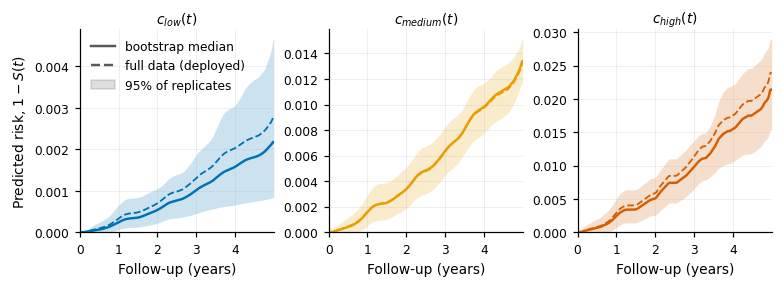

In [17]:
# ---- Figure A: threshold stability -----------------------------------------
# Every curve drawn here goes through display_smooth first. APPARENT_THRESHOLDS
# and THRESHOLD_BANDS are untouched, and every number reported anywhere else in
# the notebook is computed from those untouched arrays.
_years = TIMES / CONFIG["time_display_divisor"]

_DRAWN_APPARENT = display_smooth_ordered(APPARENT_THRESHOLDS, TIMES)
_DRAWN_BANDS = {
    key: tuple(display_smooth(component, TIMES) for component in THRESHOLD_BANDS[key])
    for key in ("c_low", "c_medium", "c_high")
}
if CONFIG["display_smoothing"]["enabled"]:
    print("Figure A is drawn from smoothed curves (cosmetic only):")
    for _k in ("c_low", "c_medium", "c_high"):
        _report_display_deviation(f"{_k} (full data)",
                                  APPARENT_THRESHOLDS[_k], _DRAWN_APPARENT[_k])
        _report_display_deviation(f"{_k} (bootstrap {_CENTRE_LABEL})",
                                  THRESHOLD_BANDS[_k][0], _DRAWN_BANDS[_k][0])
    _assert_display_only(_DRAWN_APPARENT)
_curve_meta = [
    ("c_low", "$c_{low}(t)$", CONFIG["palette_thresholds"][0]),
    ("c_medium", "$c_{medium}(t)$", CONFIG["palette_thresholds"][1]),
    ("c_high", "$c_{high}(t)$", CONFIG["palette_thresholds"][2]),
]

if CONFIG["figure_a_layout"] == "small_multiples":
    fig, axes = plt.subplots(
        1, 3, figsize=(CONFIG["figure_width_in"], 2.5), sharex=True, constrained_layout=True
    )
else:
    fig, _ax = plt.subplots(figsize=(CONFIG["figure_width_in"], 3.2), constrained_layout=True)
    axes = [_ax, _ax, _ax]

for (key, label, colour), ax in zip(_curve_meta, axes):
    centre, lo, hi = _DRAWN_BANDS[key]
    ax.fill_between(_years, lo, hi, color=colour, alpha=0.20, linewidth=0)
    ax.plot(_years, centre, color=colour, label=f"{label} bootstrap {_CENTRE_LABEL}")
    ax.plot(_years, _DRAWN_APPARENT[key], color=colour, linestyle="--",
            linewidth=1.2, label=f"{label} full data")
    ax.set_xlabel(f"Follow-up ({CONFIG['time_display_unit']})")
    ax.set_xlim(0, _cap_years)
    ax.set_ylim(bottom=0)

if CONFIG["figure_a_layout"] == "small_multiples":
    for (key, label, _c), ax in zip(_curve_meta, axes):
        ax.set_title(label, pad=4)
    axes[0].set_ylabel("Predicted risk, $1-S(t)$")
    axes[0].legend(
        handles=[
            plt.Line2D([0], [0], color="0.35", label=f"bootstrap {_CENTRE_LABEL}"),
            plt.Line2D([0], [0], color="0.35", linestyle="--", label="full data (deployed)"),
            plt.Rectangle((0, 0), 1, 1, color="0.35", alpha=0.20, label="95% of replicates"),
        ],
        loc="upper left", frameon=False,
    )
else:
    axes[0].set_ylabel("Predicted risk, $1-S(t)$")
    axes[0].legend(loc="upper left", frameon=False, ncol=2)

if CONFIG["save_figures"]:
    fig.savefig(os.path.join(OUTPUT_DIR, "figA_threshold_stability.pdf"))
    fig.savefig(os.path.join(OUTPUT_DIR, "figA_threshold_stability.png"))
plt.show()

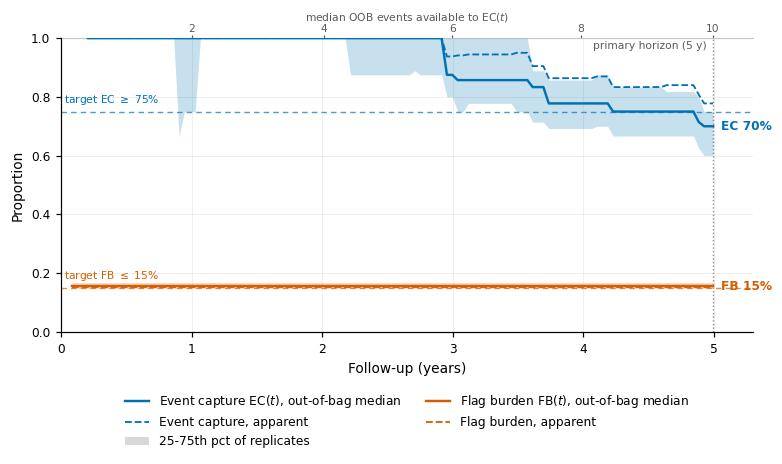

solid lines are the across-replicate median; the filled band is the 25-75th pct pointwise interval (95% reported in Table 2, not drawn) across 497 replicates; dashed lines are the full-data (apparent) values.
the second x-axis is the across-replicate median number of OOB events EC(t) is computed on; EC's spread early in follow-up is mostly that denominator.
  EC at the primary horizon: 25-75th pct [0.600, 0.750]   95% [0.400, 0.914]
  FB at the primary horizon: 25-75th pct [0.146, 0.165]   95% [0.130, 0.191]
replicates meeting the design target at the primary horizon: FB 36%, EC 31%.


In [18]:
# ---- Figure B: operating characteristics (the core evidence figure) ---------
# Band convention (CONFIG["band_inner_pctiles"] / ["band_outer_as_outline"]): the
# FILLED band is the inner one (25-75th by default) and the reported ci_alpha
# interval is a thin dotted outline. No reported number changed -- Table 2 and
# operating_characteristics.csv still carry the 2.5/97.5th percentiles. What
# changed is which of the two the eye reads first, and the reason is in the CONFIG
# comment: at this event count the 95% EC band is mostly the size of the OOB event
# set, not the stability of the rule.
_eval_years = EVAL_TIMES / CONFIG["time_display_divisor"]
_primary_year = float(CONFIG["primary_horizon"]) / CONFIG["time_display_divisor"]
_ec_colour, _fb_colour = CONFIG["palette_metrics"]
_outer_label = f"{100 * (1 - _ALPHA):.0f}%"
_inner_label = (
    f"{CONFIG['band_inner_pctiles'][0]:.0f}-{CONFIG['band_inner_pctiles'][1]:.0f}th pct"
    if CONFIG["band_inner_pctiles"] is not None else _outer_label
)

fig, ax = plt.subplots(figsize=(CONFIG["figure_width_in"], 4.1), constrained_layout=True)

ax.axvline(_primary_year, color="0.55", linewidth=0.9, linestyle=":", zorder=1)
ax.annotate(
    f"primary horizon ({_primary_year:.0f} y)",
    xy=(_primary_year, 1.0), xytext=(-4, -2),
    textcoords="offset points", ha="right", va="top",
    fontsize=CONFIG["font_size"] - 2, color="0.35",
)

_targets = CONFIG["design_targets"]
for _value, _colour, _text in (
    (_targets["min_event_capture"], _ec_colour, f"target EC $\\geq$ {_targets['min_event_capture']:.0%}"),
    (_targets["max_flag_burden"], _fb_colour, f"target FB $\\leq$ {_targets['max_flag_burden']:.0%}"),
):
    if _value is None:
        continue
    ax.axhline(_value, color=_colour, linewidth=0.9, linestyle=(0, (4, 3)), alpha=0.7, zorder=1)
    ax.annotate(_text, xy=(0.02, _value), xytext=(0, 3), textcoords="offset points",
                fontsize=CONFIG["font_size"] - 2, color=_colour, va="bottom")


def _draw_metric(centre, lo, hi, q1, q3, apparent, colour, window):
    """Filled inner band, outlined outer band, centre line, apparent line."""
    _x = _eval_years[window]
    if q1 is not None:
        ax.fill_between(_x, np.asarray(q1)[window], np.asarray(q3)[window],
                        color=colour, alpha=0.22, linewidth=0, zorder=2)
    if CONFIG["band_outer_as_outline"]:
        for _edge in (lo, hi):
            ax.plot(_x, np.asarray(_edge)[window], color=colour, linewidth=0.7,
                    linestyle=(0, (1, 1.6)), alpha=0.85, zorder=2)
    ax.plot(_x, np.asarray(centre)[window], color=colour, zorder=4)
    ax.plot(_x, np.asarray(apparent)[window], color=colour, linestyle="--",
            linewidth=1.2, zorder=4)


# Both metrics get the same treatment over the whole grid. EC's denominator is
# far smaller than FB's early on -- that is what the second x-axis is for -- but
# it is stated there rather than by drawing part of the curve differently.
_draw_metric(FB_CENTRE, FB_LO, FB_HI, FB_Q1, FB_Q3, APPARENT_FB, _fb_colour, slice(None))
_draw_metric(EC_CENTRE, EC_LO, EC_HI, EC_Q1, EC_Q3, APPARENT_EC, _ec_colour, slice(None))

# Direct labels at the primary horizon so identity never rests on colour alone.
for _curve, _colour, _tag in ((EC_CENTRE, _ec_colour, "EC"), (FB_CENTRE, _fb_colour, "FB")):
    ax.annotate(f"{_tag} {_curve[PRIMARY_J]:.0%}",
                xy=(_eval_years[PRIMARY_J], _curve[PRIMARY_J]), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=CONFIG["font_size"] - 1,
                color=_colour, fontweight="bold")

ax.set_xlabel(f"Follow-up ({CONFIG['time_display_unit']})")
ax.set_ylabel("Proportion")
ax.set_xlim(0, _cap_years * 1.06)
ax.set_ylim(0, 1.0)

# ---- second x-axis: the denominator EC(t) is computed on --------------------
# Without it the reader cannot tell that EC at 1 y rests on 1-2 events while EC
# at 5 y rests on about 10, which is the single most important caveat here.
_secax = ax.secondary_xaxis("top")
# Ticks sit on the nearest point of the EVALUATION grid to each whole year, not on
# the whole year itself: the administrative cap is 1826 d = 4.999 y, so a tick
# placed at exactly 5.0 would be off the grid and floor(_cap_years) would silently
# drop the 5-year column altogether -- the one the primary horizon is reported at.
_half_year = 0.5 * CONFIG["time_display_divisor"]
_tick_idx, _tick_pos = [], []
for _yv in range(1, int(np.floor(EVAL_TIMES.max() / CONFIG["time_display_divisor"] + 0.5)) + 1):
    _j = int(np.argmin(np.abs(EVAL_TIMES - _yv * CONFIG["time_display_divisor"])))
    if abs(EVAL_TIMES[_j] - _yv * CONFIG["time_display_divisor"]) <= _half_year:
        _tick_idx.append(_j)
        _tick_pos.append(float(_eval_years[_j]))
_secax.set_xticks(_tick_pos)
_secax.set_xticklabels([f"{EC_DEN_CENTRE[_j]:.0f}" for _j in _tick_idx])
_secax.set_xlabel("median OOB events available to EC($t$)", labelpad=2,
                  fontsize=CONFIG["font_size"] - 2, color="0.35")
_secax.tick_params(labelsize=CONFIG["font_size"] - 2, colors="0.35", length=2, pad=1)
_secax.spines["top"].set_color("0.8")

# Legend below the axes: the bands move with the data, so an in-axes legend is
# not collision-proof across re-runs with different CONFIG values.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Ordered so that matplotlib's column-major fill puts EC above FB in the left
# column and the two band entries together in the right one.
_ec_handles = [
    Line2D([], [], color=_ec_colour, linewidth=1.6,
           label=f"Event capture EC($t$), out-of-bag {_CENTRE_LABEL}"),
    Line2D([], [], color=_ec_colour, linewidth=1.2, linestyle="--",
           label="Event capture, apparent"),
    Patch(facecolor="0.45", alpha=0.28, linewidth=0,
          label=f"{_inner_label} of replicates"),
]
_fb_handles = [
    Line2D([], [], color=_fb_colour, linewidth=1.6,
           label=f"Flag burden FB($t$), out-of-bag {_CENTRE_LABEL}"),
    Line2D([], [], color=_fb_colour, linewidth=1.2, linestyle="--",
           label="Flag burden, apparent"),
]
if CONFIG["band_outer_as_outline"]:
    _fb_handles.append(Line2D([], [], color="0.45", linewidth=0.7, linestyle=(0, (1, 1.6)),
                              label=f"{_outer_label} of replicates"))
_handles = _ec_handles + _fb_handles
ax.legend(handles=_handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
          ncol=2, frameon=False)

if CONFIG["save_figures"]:
    fig.savefig(os.path.join(OUTPUT_DIR, "figB_operating_characteristics.pdf"))
    fig.savefig(os.path.join(OUTPUT_DIR, "figB_operating_characteristics.png"))
plt.show()

_band_text = (f"the filled band is the {_inner_label} and the thin dotted edges are "
              f"the {_outer_label} pointwise interval"
              if CONFIG["band_outer_as_outline"]
              else f"the filled band is the {_inner_label} pointwise interval "
                   f"({_outer_label} reported in Table 2, not drawn)")
print(f"solid lines are the across-replicate {_CENTRE_LABEL}; {_band_text} across "
      f"{len(OK_RESULTS)} replicates; dashed lines are the full-data (apparent) values.")
print("the second x-axis is the across-replicate median number of OOB events EC(t) "
      "is computed on; EC's spread early in follow-up is mostly that denominator.")
for _tag, _q1, _q3, _lo, _hi in (("EC", EC_Q1, EC_Q3, EC_LO, EC_HI),
                                 ("FB", FB_Q1, FB_Q3, FB_LO, FB_HI)):
    if _q1 is None:
        continue
    print(f"  {_tag} at the primary horizon: {_inner_label} "
          f"[{_q1[PRIMARY_J]:.3f}, {_q3[PRIMARY_J]:.3f}]   "
          f"{_outer_label} [{_lo[PRIMARY_J]:.3f}, {_hi[PRIMARY_J]:.3f}]")
print(f"replicates meeting the design target at the primary horizon: "
      f"FB {100 * FB_TARGET_HIT:.0f}%, EC {100 * EC_TARGET_HIT:.0f}%.")


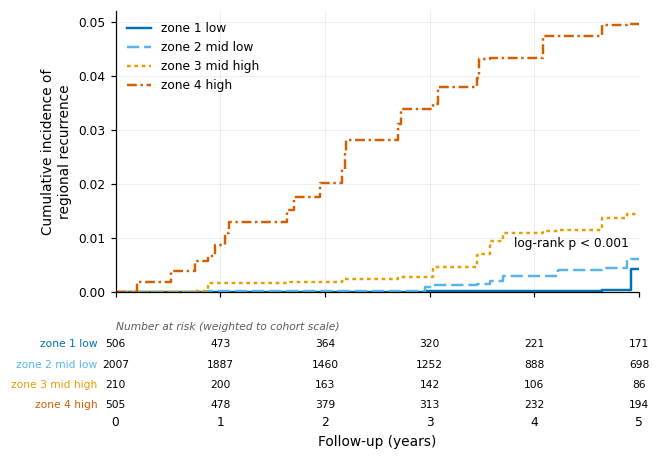

per-replicate log-rank p: median 5.594e-05, IQR 2.355e-06-0.001299, 95.4% below 0.05 (497 replicates with >= 2 occupied zones)


In [19]:
# ---- Figure C: zone separation ---------------------------------------------
# Grouping is the OOB zone at the primary horizon, pooled over replicates and
# weighted so the effective sample size is the cohort rather than 500x the cohort.
# Death without recurrence is not recorded in this dataset, so there is no competing
# event to model: this is Kaplan-Meier with a log-rank test, not Aalen-Johansen.
_zone_col = f"zone_at_{int(CONFIG['primary_horizon'])}d"
_pool = OOB_LONG[["row_index", "time", "event", _zone_col, "pool_weight"]].copy()
_pool["time"] = _pool["time"].astype(float)

fig = plt.figure(figsize=(CONFIG["figure_width_in"], 4.3))
_gs = fig.add_gridspec(2, 1, height_ratios=[3.1, 1.0], hspace=0.16,
                       left=0.30, right=0.98, top=0.98, bottom=0.13)
ax = fig.add_subplot(_gs[0])
ax_risk = fig.add_subplot(_gs[1])

_x_max_years = _cap_years
_risk_ticks = np.linspace(0.0, float(CONFIG["administrative_cap_days"]), 6)
_at_risk_rows = []
_linestyles = ["-", (0, (5, 2)), (0, (1.5, 1.5)), (0, (4, 1.5, 1, 1.5))]

for _z, _label in enumerate(CONFIG["zone_labels"]):
    _mask = _pool[_zone_col].to_numpy() == _z
    _colour = CONFIG["palette_zones"][_z]
    if _mask.sum() == 0:
        _at_risk_rows.append([np.nan] * len(_risk_ticks))
        continue
    _t = _pool.loc[_mask, "time"].to_numpy(dtype=float)
    _e = _pool.loc[_mask, "event"].to_numpy(dtype=bool)
    _w = _pool.loc[_mask, "pool_weight"].to_numpy(dtype=float)
    _et, _surv, _, _ = km_curve(_t, _e, _w)
    if _et.size:
        _steps_x = np.concatenate([[0.0], _et, [float(CONFIG["administrative_cap_days"])]])
        _steps_y = np.concatenate([[0.0], 1.0 - _surv, [1.0 - _surv[-1]]])
    else:
        _steps_x = np.array([0.0, float(CONFIG["administrative_cap_days"])])
        _steps_y = np.zeros(2)
    ax.step(_steps_x / CONFIG["time_display_divisor"], _steps_y, where="post",
            color=_colour, linestyle=_linestyles[_z], label=_label.replace("_", " "))
    _at_risk_rows.append([km_at_risk(_t, _tick, _w) for _tick in _risk_ticks])

ax.set_ylabel("Cumulative incidence of\nregional recurrence")
ax.set_xlim(0, _x_max_years)
ax.set_ylim(bottom=0)
ax.set_xticks(_risk_ticks / CONFIG["time_display_divisor"])
ax.set_xticklabels([])
ax.legend(loc="upper left", frameon=False)

# Weighted log-rank on the pooled OOB assignments.
try:
    _lr = multivariate_logrank_test(
        _pool["time"].to_numpy(dtype=float),
        _pool[_zone_col].to_numpy(),
        _pool["event"].to_numpy(dtype=bool),
        weights=_pool["pool_weight"].to_numpy(dtype=float),
    )
    _p_pooled = float(_lr.p_value)
except Exception as _exc:
    _p_pooled = np.nan
    print(f"  ! pooled log-rank failed: {type(_exc).__name__}: {_exc}")

_p_text = "p < 0.001" if _p_pooled < 1e-3 else f"p = {_p_pooled:.3f}"
ax.annotate(f"log-rank {_p_text}", xy=(0.98, 0.16), xycoords="axes fraction",
            ha="right", fontsize=CONFIG["font_size"] - 1)

# Number-at-risk table: a real x-axis underneath, rows labelled in the left margin.
_n_zones = len(CONFIG["zone_labels"])
ax_risk.set_xlim(ax.get_xlim())
ax_risk.set_ylim(-0.6, _n_zones - 0.1)
ax_risk.grid(False)
ax_risk.set_yticks([])
for _spine in ax_risk.spines.values():
    _spine.set_visible(False)
ax_risk.set_xticks(_risk_ticks / CONFIG["time_display_divisor"])
ax_risk.set_xticklabels([f"{_t / CONFIG['time_display_divisor']:.0f}" for _t in _risk_ticks])
ax_risk.tick_params(axis="x", length=0, pad=2)
ax_risk.set_xlabel(f"Follow-up ({CONFIG['time_display_unit']})")

ax_risk.text(0.0, 1.0, "Number at risk (weighted to cohort scale)",
             transform=ax_risk.transAxes, ha="left", va="top",
             fontsize=CONFIG["font_size"] - 2, style="italic", color="0.35")
for _z, _label in enumerate(CONFIG["zone_labels"]):
    _row_y = _n_zones - 1.2 - _z
    # -0.035 in axes fraction clears the widest first-column count.
    ax_risk.text(-0.035, _row_y, _label.replace("_", " "),
                 transform=ax_risk.get_yaxis_transform(), ha="right", va="center",
                 fontsize=CONFIG["font_size"] - 2, color=CONFIG["palette_zones"][_z])
    for _tick, _value in zip(_risk_ticks, _at_risk_rows[_z]):
        ax_risk.text(_tick / CONFIG["time_display_divisor"], _row_y,
                     "--" if not np.isfinite(_value) else f"{_value:.0f}",
                     ha="center", va="center", fontsize=CONFIG["font_size"] - 2)

if CONFIG["save_figures"]:
    fig.savefig(os.path.join(OUTPUT_DIR, "figC_zone_separation.pdf"))
    fig.savefig(os.path.join(OUTPUT_DIR, "figC_zone_separation.png"))
plt.show()

# Per-replicate log-rank, which does not depend on the pooling weight at all.
_per_rep_p = []
for _r in OK_RESULTS:
    _f = _r["oob"]
    if _f[_zone_col].nunique() < 2:
        continue
    try:
        _per_rep_p.append(float(multivariate_logrank_test(
            _f["time"].to_numpy(dtype=float),
            _f[_zone_col].to_numpy(),
            _f["event"].to_numpy(dtype=bool),
        ).p_value))
    except Exception:
        continue
if _per_rep_p:
    _per_rep_p = np.asarray(_per_rep_p, dtype=float)
    print(f"per-replicate log-rank p: median {np.median(_per_rep_p):.4g}, "
          f"IQR {np.percentile(_per_rep_p, 25):.4g}-{np.percentile(_per_rep_p, 75):.4g}, "
          f"{100 * np.mean(_per_rep_p < 0.05):.1f}% below 0.05 "
          f"({_per_rep_p.size} replicates with >= 2 occupied zones)")

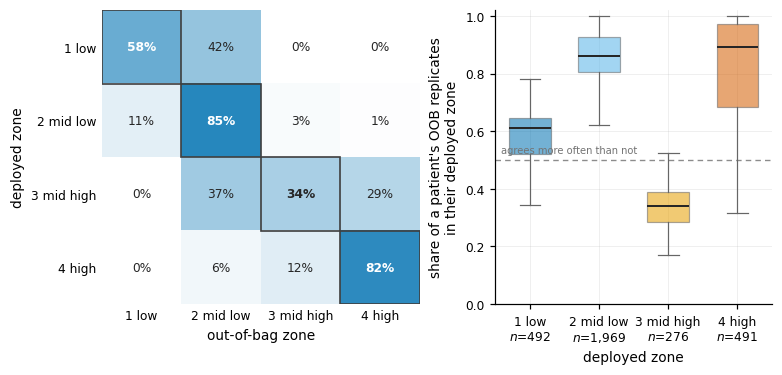

zone stability at the primary horizon (5 y), 497 replicates, per-patient weighting:
  deployed_zone  n_patients  mean_share_in_deployed_zone  median_patient_agreement  share_of_patients_agreeing_over_half  mean_share_adjacent_zone  mean_share_two_or_more_zones_away
     zone_1_low         492                        0.583                     0.611                                 0.766                     0.416                              0.000
 zone_2_mid_low        1969                        0.849                     0.862                                 0.999                     0.140                              0.010
zone_3_mid_high         276                        0.338                     0.342                                 0.007                     0.661                              0.001
    zone_4_high         491                        0.823                     0.893                                 0.955                     0.121                              0.056

avera

In [20]:
# ---- Figure D: zone stability -----------------------------------------------
# Figures A-C describe the curves and the cohort. This one describes the patient:
# of the ~185 replicates in which a given patient was out-of-bag, how often did
# the refitted-and-rederived system put them in the zone the deployed system puts
# them in? That is the question a clinician actually faces ("would this label
# survive a repeat of the study?") and no other output answers it.
#
# Weighting: the per-patient zone distribution is computed FIRST, then averaged
# across the patients of a deployed zone, so every patient counts once regardless
# of how many replicates they happened to be out-of-bag in (146-223 here). Pooling
# the patient-replicate rows directly would weight patients by their OOB count.
from matplotlib.colors import LinearSegmentedColormap

_zone_short = [f"{i + 1} {' '.join(lbl.split('_')[2:])}"
               for i, lbl in enumerate(CONFIG["zone_labels"])]
_n_zones = len(_zone_short)


def zone_stability(horizon):
    """(matrix, agreement) at one horizon.

    matrix[k, j] : for patients the deployed system puts in zone k, the mean
                   share of their OOB replicates that put them in zone j.
                   Each row is a mean of probability vectors, so it sums to 1.
    agreement    : per-patient share of OOB replicates matching the deployed zone,
                   as a Series indexed by row_index.
    """
    col = f"zone_at_{int(horizon)}d"
    counts = (OOB_LONG.groupby(["row_index", col]).size()
              .unstack(fill_value=0)
              .reindex(columns=range(_n_zones), fill_value=0))
    shares = counts.div(counts.sum(axis=1), axis=0)
    rows = shares.index.to_numpy()
    deployed = APPARENT_ZONES[rows, HORIZON_IDX[float(horizon)]]
    matrix = np.full((_n_zones, _n_zones), np.nan)
    for k in range(_n_zones):
        sel = deployed == k
        if sel.any():
            matrix[k] = shares.to_numpy()[sel].mean(axis=0)
    agreement = pd.Series(
        shares.to_numpy()[np.arange(rows.size), deployed], index=rows, name="agreement"
    )
    return matrix, agreement, deployed


_primary = float(CONFIG["primary_horizon"])
ZONE_STABILITY = {h: zone_stability(h) for h in CONFIG["reporting_horizons"]}
_matrix, _agreement, _deployed = ZONE_STABILITY[_primary]

_zone_colours = CONFIG["palette_zones"]
_cmap = LinearSegmentedColormap.from_list("zone_seq", ["#FFFFFF", CONFIG["palette_zones"][0]])

fig, (ax_m, ax_b) = plt.subplots(
    1, 2, figsize=(CONFIG["figure_width_in"], 3.3),
    gridspec_kw={"width_ratios": [1.15, 1.0]}, constrained_layout=True,
)

# ---- left: where a deployed zone's patients actually land -------------------
ax_m.imshow(_matrix, cmap=_cmap, vmin=0.0, vmax=1.0, aspect="auto")
for k in range(_n_zones):
    for j in range(_n_zones):
        if not np.isfinite(_matrix[k, j]):
            continue
        ax_m.text(j, k, f"{_matrix[k, j]:.0%}", ha="center", va="center",
                  fontsize=CONFIG["font_size"] - 1,
                  color="white" if _matrix[k, j] > 0.55 else "0.15",
                  fontweight="bold" if k == j else "normal")
    # The diagonal is the reproducibility of the deployed label; outline it so the
    # eye reads down it rather than scanning the whole grid.
    ax_m.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False,
                                 edgecolor="0.25", linewidth=1.1, zorder=3))
ax_m.set_xticks(range(_n_zones), _zone_short)
ax_m.set_yticks(range(_n_zones), _zone_short)
ax_m.set_xlabel("out-of-bag zone")
ax_m.set_ylabel("deployed zone")
ax_m.grid(False)
for _sp in ax_m.spines.values():
    _sp.set_visible(False)
ax_m.tick_params(length=0)

# ---- right: is the average hiding a mix of stable and unstable patients? ----
_groups = [_agreement.to_numpy()[_deployed == k] for k in range(_n_zones)]
_present = [k for k in range(_n_zones) if _groups[k].size]
_bp = ax_b.boxplot([_groups[k] for k in _present], vert=True, widths=0.6,
                   patch_artist=True, showfliers=False,
                   medianprops=dict(color="0.15", linewidth=1.3),
                   whiskerprops=dict(color="0.4", linewidth=0.8),
                   capprops=dict(color="0.4", linewidth=0.8),
                   boxprops=dict(linewidth=0.8, edgecolor="0.4"))
for _patch, k in zip(_bp["boxes"], _present):
    _patch.set_facecolor(_zone_colours[k])
    _patch.set_alpha(0.55)
ax_b.set_xticks(range(1, len(_present) + 1),
                [f"{_zone_short[k]}\n$n$={_groups[k].size:,d}" for k in _present])
ax_b.set_ylim(0, 1.02)
ax_b.set_ylabel("share of a patient's OOB replicates\nin their deployed zone")
ax_b.set_xlabel("deployed zone")
ax_b.axhline(0.5, color="0.55", linewidth=0.9, linestyle=(0, (4, 3)), zorder=1)
ax_b.annotate("agrees more often than not", xy=(0.02, 0.5), xycoords=("axes fraction", "data"),
              xytext=(0, 3), textcoords="offset points",
              fontsize=CONFIG["font_size"] - 2.5, color="0.45", va="bottom")

if CONFIG["save_figures"]:
    fig.savefig(os.path.join(OUTPUT_DIR, "figD_zone_stability.pdf"))
    fig.savefig(os.path.join(OUTPUT_DIR, "figD_zone_stability.png"))
plt.show()

# ---- the same numbers at every reporting horizon, as a table ---------------
_rows = []
for _h in CONFIG["reporting_horizons"]:
    _mat, _agr, _dep = ZONE_STABILITY[_h]
    for k in range(_n_zones):
        _sel = _dep == k
        _rows.append({
            "horizon_days": int(_h),
            "horizon_years": round(float(_h) / CONFIG["time_display_divisor"], 2),
            "deployed_zone": CONFIG["zone_labels"][k],
            "n_patients": int(_sel.sum()),
            "mean_share_in_deployed_zone": float(_mat[k, k]) if np.isfinite(_mat[k, k]) else np.nan,
            "median_patient_agreement": float(np.median(_agr.to_numpy()[_sel])) if _sel.any() else np.nan,
            "share_of_patients_agreeing_over_half": (
                float(np.mean(_agr.to_numpy()[_sel] > 0.5)) if _sel.any() else np.nan),
            "mean_share_adjacent_zone": float(
                np.nansum([_mat[k, j] for j in (k - 1, k + 1) if 0 <= j < _n_zones])),
            "mean_share_two_or_more_zones_away": float(
                np.nansum([_mat[k, j] for j in range(_n_zones) if abs(j - k) >= 2])),
        })
ZONE_STABILITY_TABLE = pd.DataFrame(_rows)
if CONFIG["save_tables"]:
    ZONE_STABILITY_TABLE.to_csv(
        os.path.join(OUTPUT_DIR, "table3_zone_stability.csv"), index=False)

print(f"zone stability at the primary horizon "
      f"({_primary / CONFIG['time_display_divisor']:.0f} y), "
      f"{len(OK_RESULTS)} replicates, per-patient weighting:")
print(ZONE_STABILITY_TABLE[ZONE_STABILITY_TABLE["horizon_days"] == int(_primary)]
      .drop(columns=["horizon_days", "horizon_years"]).round(3).to_string(index=False))
_off = float(np.nanmean([1.0 - _matrix[k, k] for k in range(_n_zones)]))
print(f"\naveraged over the four deployed zones, a patient lands OUTSIDE their "
      f"deployed zone in {_off:.0%} of the replicates they are out-of-bag in.")
print("rows of the left panel sum to 100%; the diagonal is the reproducibility of "
      "the deployed label, and distance from it is how far the label moves when it moves.")


## 6.2 Tables

Table 1 reports zone occupancy and outcome at each reporting horizon, OOB beside apparent so
the optimism is explicit. Table 2 reports the two design criteria at the primary horizon.

In [21]:
# ---- Table export helper ----------------------------------------------------
def export_table(frame, stem, n_label_cols=1):
    """Write a table as CSV and as LaTeX with booktabs rules."""
    if not CONFIG["save_tables"]:
        return None, None
    csv_path = os.path.join(OUTPUT_DIR, f"{stem}.csv")
    tex_path = os.path.join(OUTPUT_DIR, f"{stem}.tex")
    frame.to_csv(csv_path, index=False)
    column_format = "l" * n_label_cols + "r" * (frame.shape[1] - n_label_cols)
    styler = (
        frame.style
        .hide(axis="index")
        .format(escape="latex", na_rep="--")
        .format_index(escape="latex", axis=1)      # headers contain % and [ ]
    )
    with open(tex_path, "w", encoding="utf-8") as handle:
        handle.write(styler.to_latex(hrules=True, column_format=column_format))
    return csv_path, tex_path


def _fmt_ci(mean, lo, hi, as_pct=False, decimals=3):
    if not np.isfinite(mean):
        return "--"
    if as_pct:
        body = f"{100 * mean:.1f}"
        interval = (f" [{100 * lo:.1f}, {100 * hi:.1f}]"
                    if np.isfinite(lo) and np.isfinite(hi) else "")
        return body + interval
    body = f"{mean:.{decimals}f}"
    interval = (f" [{lo:.{decimals}f}, {hi:.{decimals}f}]"
                if np.isfinite(lo) and np.isfinite(hi) else "")
    return body + interval


# ---- Table 1: zone summary --------------------------------------------------
# A zone that is empty in some replicates yields all-NaN slices; that is the
# intended behaviour (spec: propagate NaN, do not substitute), so the warning is
# suppressed rather than the NaN being filled.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    _agg = (
        ZONE_LONG
        .groupby(["horizon", "zone", "zone_label"], observed=True)
        .agg(
            n_mean=("n", _CENTRE),
            pct_mean=("pct", _CENTRE),
            pct_lo=("pct", lambda s: np.nanpercentile(s, _PCTILES[0])),
            pct_hi=("pct", lambda s: np.nanpercentile(s, _PCTILES[1])),
            events_mean=("observed_events", _CENTRE),
            cif_mean=("cif", _CENTRE),
            cif_lo=("cif", lambda s: np.nanpercentile(s, _PCTILES[0])),
            cif_hi=("cif", lambda s: np.nanpercentile(s, _PCTILES[1])),
            n_replicates=("cif", "size"),
            n_replicates_empty=("n", lambda s: int((np.asarray(s) <= 0).sum())),
        )
        .reset_index()
    )
_apparent_lookup = APPARENT_ZONE_SUMMARY.set_index(["horizon", "zone"])

_rows = []
for _, _r in _agg.iterrows():
    _app = _apparent_lookup.loc[(_r["horizon"], _r["zone"])]
    _rows.append({
        "Horizon (y)": f"{_r['horizon'] / CONFIG['time_display_divisor']:.0f}",
        "Zone": _r["zone_label"].replace("_", " "),
        "N/repl. (OOB)": f"{_r['n_mean']:.0f}",
        "% (OOB) [95% CI]": _fmt_ci(_r["pct_mean"], _r["pct_lo"], _r["pct_hi"], as_pct=True),
        "Events/repl. (OOB)": f"{_r['events_mean']:.1f}",
        "CIF (OOB) [95% CI]": _fmt_ci(_r["cif_mean"], _r["cif_lo"], _r["cif_hi"], as_pct=True),
        "N (app.)": f"{_app['n']:.0f}",
        "% (app.)": f"{100 * _app['pct']:.1f}" if np.isfinite(_app["pct"]) else "--",
        "Events (app.)": f"{_app['observed_events']:.0f}",
        "CIF (app.) [95% CI]": _fmt_ci(_app["cif"], _app["cif_lo"], _app["cif_hi"], as_pct=True),
        "Empty in": f"{int(_r['n_replicates_empty'])}/{int(_r['n_replicates'])}",
    })
TABLE1 = pd.DataFrame(_rows)
export_table(TABLE1, "table1_zone_summary", n_label_cols=2)
print(f"Table 1 - zone summary. Percentages and cumulative incidence are in %; OOB values are "
      f"the {_CENTRE_LABEL} across replicates with the 2.5-97.5th percentile interval beside them.")
print(TABLE1.to_string(index=False))
print("\nOOB counts are per replicate (each replicate holds out ~37% of the cohort), so only "
      "the % and CIF columns are directly comparable with the apparent ones.")
print("'Empty in' counts replicates that placed zero OOB patients in that zone; those "
      "replicates contribute NaN rather than a substituted value.")

# ---- Table 2: design criteria ----------------------------------------------
_h = float(CONFIG["primary_horizon"])
_h_years = _h / CONFIG["time_display_divisor"]
TABLE2 = pd.DataFrame([
    {
        "Criterion": f"Flag burden at {_h_years:.0f} y",
        "Apparent": f"{100 * APPARENT_FB[PRIMARY_J]:.1f}",
        f"OOB {_CENTRE_LABEL} [95% CI]": _fmt_ci(FB_CENTRE[PRIMARY_J], FB_LO[PRIMARY_J], FB_HI[PRIMARY_J], as_pct=True),
        "Optimism": f"{100 * (APPARENT_FB[PRIMARY_J] - FB_CENTRE[PRIMARY_J]):+.1f}",
        "Target": ("--" if CONFIG["design_targets"]["max_flag_burden"] is None
                   else f"max {100 * CONFIG['design_targets']['max_flag_burden']:.0f}"),
        "% repl. meeting": ("--" if not np.isfinite(FB_TARGET_HIT)
                            else f"{100 * FB_TARGET_HIT:.0f}"),
    },
    {
        "Criterion": f"Event capture at {_h_years:.0f} y",
        "Apparent": f"{100 * APPARENT_EC[PRIMARY_J]:.1f}",
        f"OOB {_CENTRE_LABEL} [95% CI]": _fmt_ci(EC_CENTRE[PRIMARY_J], EC_LO[PRIMARY_J], EC_HI[PRIMARY_J], as_pct=True),
        "Optimism": f"{100 * (APPARENT_EC[PRIMARY_J] - EC_CENTRE[PRIMARY_J]):+.1f}",
        "Target": ("--" if CONFIG["design_targets"]["min_event_capture"] is None
                   else f"min {100 * CONFIG['design_targets']['min_event_capture']:.0f}"),
        "% repl. meeting": ("--" if not np.isfinite(EC_TARGET_HIT)
                            else f"{100 * EC_TARGET_HIT:.0f}"),
    },
])
export_table(TABLE2, "table2_design_criteria", n_label_cols=1)
print(f"\nTable 2 - design criteria at the primary horizon (all values in %, "
      f"{len(OK_RESULTS)} replicates)")
print(TABLE2.to_string(index=False))

if CONFIG["save_tables"]:
    OPERATING_CHARACTERISTICS.to_csv(
        os.path.join(OUTPUT_DIR, "operating_characteristics.csv"), index=False
    )

Table 1 - zone summary. Percentages and cumulative incidence are in %; OOB values are the median across replicates with the 2.5-97.5th percentile interval beside them.
Horizon (y)            Zone N/repl. (OOB)  % (OOB) [95% CI] Events/repl. (OOB) CIF (OOB) [95% CI] N (app.) % (app.) Events (app.) CIF (app.) [95% CI] Empty in
          1      zone 1 low           283  24.6 [1.1, 51.9]                0.0     0.0 [0.0, 0.0]      657     20.4             0      0.0 [0.0, 0.0]   15/497
          1  zone 2 mid low           658 55.4 [31.0, 77.3]                0.0     0.0 [0.0, 0.2]     1826     56.6             0      0.0 [0.0, 0.0]    2/497
          1 zone 3 mid high            59   5.3 [0.6, 14.6]                0.0     0.0 [0.0, 2.5]      254      7.9             0      0.0 [0.0, 0.0]   45/497
          1     zone 4 high           184 15.5 [13.0, 19.1]                2.0     0.9 [0.0, 2.0]      491     15.2             5      1.0 [0.4, 2.5]    0/497
          3      zone 1 low          

### 6.2.1 Threshold optimism

Figure A shows the deployed curve against the bootstrap band; Table 4 states the gap.
The comparison is a ratio (OOB centre / deployed) so the three curves, which differ by
an order of magnitude in level, can be read on one scale. A ratio below 1 means the
deployed cutoff sits above what the out-of-bag resamples support: on `c_low` that is a
wider low-risk zone than the evidence carries, which is the safety-relevant direction.

In [22]:
# ---- Table 4: threshold optimism -------------------------------------------
# Figure A draws the deployed curve inside the bootstrap band; this states the
# gap as a number. For each curve and reporting horizon: the deployed
# (full-cohort) cutoff, and the ratio of the OOB bootstrap centre to it with the
# 2.5-97.5th percentile interval of that ratio across replicates.
#
# The ratio rather than the difference, because the three curves differ by an
# order of magnitude in level (c_low is ~0.3 per 1000 at 1 y, c_high ~24 per
# 1000 at 5 y), so a shared difference scale is unreadable and a per-curve one
# is not comparable between rows.
#
# How to read the direction. Ratio < 1 means the deployed cutoff sits ABOVE the
# level the out-of-bag resamples support. On c_low that widens the low-risk
# zone: patients are called low risk on a boundary the resamples do not
# reproduce, which is the safety-relevant direction of the error. On c_high the
# same sign narrows the flagged set, and ratio > 1 widens it.
#
# This is an optimism statement about the CURVES, in the same sense that
# Table 2's `Optimism` column is one about the operating characteristics. It is
# descriptive: nothing here corrects the deployed curves, which remain the
# full-cohort ones exported in deployed_thresholds.csv.
_THRESH_MATRICES = {
    key: np.vstack([r[key] for r in OK_RESULTS]).astype(float)
    for key in ("c_low", "c_medium", "c_high")
}
_PER_MILLE = 1000.0
_ratio_rows = []
_ratio_long = []
for _key in ("c_low", "c_medium", "c_high"):
    _mat = _THRESH_MATRICES[_key]
    _dep = DEPLOYED_THRESHOLDS[_key].to_numpy(dtype=float)
    _row = {"Curve": _key}
    for _h in CONFIG["reporting_horizons"]:
        _j = TIME_TO_IDX[float(_h)]
        _hy = float(_h) / CONFIG["time_display_divisor"]
        _d = float(_dep[_j])
        _col = _mat[:, _j]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            _centre = (np.nanmedian(_col) if _CENTRE == "median" else np.nanmean(_col))
            _below = float(np.nanmean(_col < _d))
        _row[f"{_hy:.0f} y deployed (per 1000)"] = f"{_PER_MILLE * _d:.2f}"
        if _d > 0.0:
            # d is a constant within a column, so the centre of the ratios and
            # the ratio of the centres agree for both the median and the mean.
            _ratios = _col / _d
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                _rc = (np.nanmedian(_ratios) if _CENTRE == "median"
                       else np.nanmean(_ratios))
                _rlo, _rhi = np.nanpercentile(_ratios, _PCTILES)
            _row[f"{_hy:.0f} y OOB/deployed [95% CI]"] = (
                f"{_rc:.2f} [{_rlo:.2f}, {_rhi:.2f}]"
            )
        else:
            # A deployed cutoff of exactly zero has no meaningful ratio; the
            # absolute columns still carry the comparison.
            _rc = _rlo = _rhi = np.nan
            _row[f"{_hy:.0f} y OOB/deployed [95% CI]"] = "--"
        _ratio_long.append({
            "curve": _key,
            "horizon_days": float(_h),
            "horizon_years": _hy,
            "deployed": _d,
            f"oob_{_CENTRE}": float(_centre),
            "oob_lo": float(np.nanpercentile(_col, _PCTILES[0])),
            "oob_hi": float(np.nanpercentile(_col, _PCTILES[1])),
            "ratio_centre": float(_rc),
            "ratio_lo": float(_rlo),
            "ratio_hi": float(_rhi),
            "share_replicates_below_deployed": _below,
            "n_replicates": int(_col.size),
        })
    _ratio_rows.append(_row)

TABLE4 = pd.DataFrame(_ratio_rows)
THRESHOLD_OPTIMISM = pd.DataFrame(_ratio_long)
export_table(TABLE4, "table4_threshold_optimism", n_label_cols=1)
if CONFIG["save_tables"]:
    THRESHOLD_OPTIMISM.to_csv(
        os.path.join(OUTPUT_DIR, "table4_threshold_optimism_long.csv"), index=False
    )

print(f"\nTable 4 - threshold optimism ({len(OK_RESULTS)} replicates, OOB centre = "
      f"{_CENTRE_LABEL}). Cutoffs are risk per 1000 patients; the second column of "
      f"each horizon is the OOB centre divided by the deployed value.")
print(TABLE4.to_string(index=False))

# The claim the table is making, stated so it cannot be missed in the CSV.
for _key in ("c_low", "c_medium", "c_high"):
    _sub = THRESHOLD_OPTIMISM[THRESHOLD_OPTIMISM["curve"] == _key]
    _rr = _sub["ratio_centre"].to_numpy(dtype=float)
    _bl = _sub["share_replicates_below_deployed"].to_numpy(dtype=float)
    print(f"  {_key:9s} OOB/deployed {np.nanmin(_rr):.2f}-{np.nanmax(_rr):.2f} "
          f"across the reporting horizons; replicates below the deployed curve: "
          f"{', '.join(f'{100 * b:.0f}%' for b in _bl)}")
print("  ratio < 1 = the deployed cutoff sits above what the resamples support "
      "(for c_low: a wider low-risk zone than the OOB evidence carries).")


Table 4 - threshold optimism (497 replicates, OOB centre = median). Cutoffs are risk per 1000 patients; the second column of each horizon is the OOB centre divided by the deployed value.
   Curve 1 y deployed (per 1000) 1 y OOB/deployed [95% CI] 3 y deployed (per 1000) 3 y OOB/deployed [95% CI] 5 y deployed (per 1000) 5 y OOB/deployed [95% CI]
   c_low                    0.33         0.73 [0.21, 1.94]                    1.30         0.78 [0.34, 1.43]                    2.76         0.79 [0.30, 1.69]
c_medium                    1.64         0.97 [0.30, 1.79]                    6.31         1.00 [0.72, 1.30]                   13.16         1.02 [0.89, 1.15]
  c_high                    2.83         0.82 [0.21, 1.78]                   11.08         0.87 [0.56, 1.22]                   23.92         0.89 [0.64, 1.21]
  c_low     OOB/deployed 0.73-0.79 across the reporting horizons; replicates below the deployed curve: 73%, 76%, 69%
  c_medium  OOB/deployed 0.97-1.02 across the reporting hor

## 7. Regression test

Setting the bootstrap sample equal to the full cohort must leave the OOB metrics undefined and
must reproduce the single-fit numbers exactly for the apparent metrics.

In [23]:
# ---- Regression test (spec section 7) --------------------------------------
if CONFIG["run_regression_test"]:
    _original_sampler = bootstrap_indices

    def _full_cohort_sampler(rng, event, stratify_on_event):
        return np.arange(N_PATIENTS)

    try:
        bootstrap_indices = _full_cohort_sampler
        _regression = run_replicate(-1, 0)
    finally:
        bootstrap_indices = _original_sampler

    assert _regression["ok"] is False, "a full-cohort in-bag set must leave no OOB patients"
    assert "empty out-of-bag" in _regression["error"], _regression["error"]
    print(f"OOB metrics undefined when in-bag == full cohort: {_regression['error']}")

    # Undefined, not zero: the metric primitives propagate NaN on an empty sample.
    _empty = np.empty(0, dtype=float)
    assert np.all(np.isnan(flag_burden_curve(_empty, EVAL_TIMES)))
    _ec_empty, _, _ = event_capture_curve(_empty, np.empty(0, bool), _empty, EVAL_TIMES)
    assert np.all(np.isnan(_ec_empty))
    assert np.all(np.isnan(list(km_cif_at(_empty, np.empty(0, bool), _h, _ALPHA))))
    print("empty-sample metrics propagate NaN rather than substituting a value")

    # Apparent side: refitting the same fixed configuration on the full cohort must
    # land on exactly the deployed curves.
    _check_model = MODEL_FACTORY().fit(X, y)
    _check = derive_thresholds(
        predict_risk_trajectory(_check_model, X, TIMES), y, TIMES, **CONFIG["threshold_params"]
    )
    for _key in ("c_low", "c_medium", "c_high"):
        _delta = float(np.max(np.abs(_check[_key] - APPARENT_THRESHOLDS[_key])))
        assert _delta == 0.0, f"{_key} differs by {_delta:.3e} on a repeat full-cohort fit"
    print("full-cohort refit reproduces the deployed threshold curves exactly")
else:
    print("regression test skipped (CONFIG['run_regression_test'] is False)")

OOB metrics undefined when in-bag == full cohort: ValueError: empty out-of-bag set
empty-sample metrics propagate NaN rather than substituting a value
full-cohort refit reproduces the deployed threshold curves exactly


In [24]:
# ---- What was written -------------------------------------------------------
print(f"output directory: {OUTPUT_DIR}\n")
for _name in sorted(os.listdir(OUTPUT_DIR)):
    _size = os.path.getsize(os.path.join(OUTPUT_DIR, _name))
    print(f"  {_name:<42s} {_size / 1024:>10.1f} KB")
print(f"\nreplicates: {len(OK_RESULTS)} used, {len(FAILED_RESULTS)} degenerate, "
      f"seed {CONFIG['random_seed']}")

output directory: c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\threshold_validation

  2_figA_threshold_stability.png                  176.9 KB
  _display_smoothing_check.png                     58.5 KB
  deployed_thresholds.csv                         157.7 KB
  figA_threshold_stability.pdf                    118.4 KB
  figA_threshold_stability.png                    176.0 KB
  figB_operating_characteristics.pdf               26.9 KB
  figB_operating_characteristics.png              128.3 KB
  figC_zone_separation.pdf                         21.6 KB
  figC_zone_separation.png                        140.3 KB
  figD_zone_stability.pdf                          23.8 KB
  figD_zone_stability.png                         146.4 KB
  high_threshold_stages.pdf                        18.9 KB
  high_threshold_stages.png                       188.1 KB
  operating_characteristics.csv                    32.3 KB
  replicate_failures.csv.gz                    